# AI-Based Human Pose Estimation Using Five IMU Sensors - All 6 Motions

Predict **17 body keypoints × 3D = 51 pose values** from **five IMU sensors × 6 channels = 30 input values** (time series, sampled frame by frame).

This notebook extends the single-motion notebook to **6 motion recordings (6 CSV files)**. Each dataset contains **50 samples of the same motion**, recorded at a sampling rate of **20 Hz (20 samples per second)**.

## Sensor Placement and Motion Recording Protocol

### IMU Sensor Positions

Five IMU sensors are attached to the following body positions:

| Sensor | Position |
|---|---|
| **IMU 1** | Forehead |
| **IMU 2** | Right wrist |
| **IMU 3** | Left wrist |
| **IMU 4** | Right ankle |
| **IMU 5** | Left ankle |

### Motion Recording Conditions

- All motions are captured with the **human facing the camera at the start of the recording**.
- The subject starts in a forward-facing standing position, with the body oriented toward the camera.
- **No turning is performed during the recordings.** The subject maintains a forward-facing orientation while performing each motion.
- Each dataset contains 50 repetitions of the same motion performed at different speeds to capture variations in movement speed and temporal patterns.
- The IMU sensors are sampled at a consistent rate of **20 Hz**, corresponding to a sampling interval of **50 milliseconds**.
- The five IMU sensors provide 30 input channels in total (5 sensors × 6 channels: 3-axis accelerometer and 3-axis gyroscope).
- The corresponding computer-vision ground truth provides 17 body keypoints in 3D, resulting in 51 pose values per frame.

## Motion Datasets

| # | Motion | File | Description |
|---|---|---|---|
| 1 | **Right Arm Lateral Raise** | `Right Arm Lateral Raise.csv` | One arm moves out to the side in a smooth arc, then returns down toward the body. The other arm stays relaxed at the side. |
| 2 | **Left Arm Lateral Raise** | `Left Arm Lateral Raise.csv` | The opposite arm moves out to the side in a smooth arc, then returns down toward the body. The other arm stays relaxed at the side. |
| 3 | **Double Arm Swing** | `Double Arm Swing.csv` | Both arms move outward and upward together in a symmetrical arc, then return down toward the body. |
| 4 | **Standing Forward Fold** | `Standing Forward Fold.csv` | The upper body bends forward at the waist with the head and arms hanging down, then rises back up to an upright position. |
| 5 | **Right Knee March** | `Right Knee March.csv` | One knee lifts in front of the body with the foot hanging below it, then the foot lowers back down to the floor. |
| 6 | **Left Knee March** | `Left Knee March.csv` | The opposite knee lifts in front of the body with the foot hanging below it, then the foot lowers back down to the floor. |

## Pipeline

| Part | What it does |
|---|---|
| **A. Per-motion experiments** | For *each* of the 6 motions: load, clean, block-wise split, scale, sliding windows, train 5 models (MLP, 1D-CNN, GRU, LSTM, Transformer) + 2 reference baselines, evaluate (MAE, RMSE, MPJPE, R² variants). |
| **B. Summary of all motions** | One table with every motion × model result, best model per motion, a motion × model MPJPE matrix and the average ranking of the models. |
| **C. Combined model** | All 6 datasets are merged into one training set and the same 5 models are trained on the whole dataset. Results are reported overall **and per motion**, and compared with the single-motion models. |

## Time-Series Rules Followed Everywhere (No Leakage)

- Each motion is split *inside its own recording* into 12 contiguous blocks (train / val / test) with a purge gap.
- Sliding windows are built **inside each contiguous segment of each motion**. No window ever crosses a block boundary or a motion boundary, so merging the 6 files never creates fake "transitions" between motions.
- Scalers are fit on **training rows only** (per motion in Part A, on all motions' training rows in Part C).
- Each window predicts the pose at its **last frame** (only past + current IMU samples, no look-ahead).
- The test blocks of Part A and Part C are the **same frames**, so the two results are directly comparable.
- **Model selection uses validation MPJPE only.** Test numbers are reported, never used to choose a model.



## 1. Imports, configuration and reproducibility

The six CSV files are located automatically  

In [1]:
import os, re, json, time, glob, random, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor
import joblib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display, Image

warnings.filterwarnings("ignore")

DATA_DIR     = "/kaggle/input/datasets/bahasurunayanakantha/imu-mediapipe-motion-capture-dataset"

# (motion name, csv file, body group, description) -- order = order used in every table and figure
MOTION_SPEC = [
    ("Right Arm Lateral Raise", "Right Arm Lateral Raise.csv", "Arm",
     "One arm moves out to the side in a smooth arc, then returns down toward the body. The other arm stays relaxed at the side."),
    ("Left Arm Lateral Raise", "Left Arm Lateral Raise.csv", "Arm",
     "The opposite arm moves out to the side in a smooth arc, then returns down toward the body. The other arm stays relaxed at the side."),
    ("Double Arm Swing", "Double Arm Swing.csv", "Arm",
     "Both arms move outward and upward together in a symmetrical arc, then return down toward the body."),
    ("Standing Forward Fold", "Standing Forward Fold.csv", "Trunk",
     "The upper body bends forward at the waist with the head and arms hanging down, then rises back up to an upright position."),
    ("Right Knee March", "Right Knee March.csv", "Leg",
     "One knee lifts in front of the body with the foot hanging below it, then the foot lowers back down to the floor."),
    ("Left Knee March", "Left Knee March.csv", "Leg",
     "The opposite knee lifts in front of the body with the foot hanging below it, then the foot lowers back down to the floor."),
]
N_EXPECTED_MOTIONS = 6

# Missing IMU packets: NaN runs up to this many frames are linearly interpolated (20 Hz -> 5 frames = 0.25 s);
# longer runs stay missing and are zero-filled (= training mean) after scaling.
MAX_INTERP_GAP = 5

# Sequence / split settings (same as the single-motion notebook)
WINDOW_SIZE = 10
STRIDE      = 1
SPLIT_MODE  = "blocked"          # "blocked" (recommended) or "chrono"
N_BLOCKS    = 12
VAL_BLOCKS  = {2, 8}
TEST_BLOCKS = {5, 11}
GAP         = WINDOW_SIZE

# Training settings
EPOCHS              = 300        # upper bound, EarlyStopping decides
BATCH_SIZE          = 64         # Part A (per motion)
BATCH_SIZE_COMBINED = 128        # Part C (about 6x more windows)
N_SEEDS_MOTION      = 3          # seeds averaged per model in Part A (6 motions x 5 models; use 3 for the final run)
N_SEEDS_COMBINED    = 3          # seeds averaged per model in Part C
LOSS_FLOOR          = 0.25
NOISE_STD           = 0.10
SENSOR_DROPOUT      = 0.05

RESUME     = True                # Part A: skip motions whose results/per_motion/*_summary.csv already exists
QUICK_TEST = False               # True -> 3 epochs, 1 seed: only to check that the whole notebook runs

if QUICK_TEST:
    EPOCHS, N_SEEDS_MOTION, N_SEEDS_COMBINED, RESUME = 3, 1, 1, False

# Cached Part A results are keyed by this tag, so a QUICK_TEST run or a run with other settings
# can never be silently reused by a later full run.
CONFIG_TAG = f"{SPLIT_MODE}_w{WINDOW_SIZE}_b{N_BLOCKS}_e{EPOCHS}_s{N_SEEDS_MOTION}"

# ----------------------------------------------------------------------------------
# Reproducibility
# ----------------------------------------------------------------------------------
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        try: tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError: pass
    print(f"GPU(s) detected: {[g.name for g in gpus]}. Using float32.")
else:
    print("No GPU detected: running on CPU in float32 (Part A/C will be slow).")
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

# ----------------------------------------------------------------------------------
# Folders
# ----------------------------------------------------------------------------------
DIR_FIGURES = "figures"
DIR_MODELS  = "saved_models"
DIR_SCALERS = "saved_scalers"
DIR_RESULTS = "results"
DIR_LOGS    = "logs/tensorboard"
DIR_PM      = os.path.join(DIR_RESULTS, "per_motion")
for d in [DIR_FIGURES, DIR_MODELS, DIR_SCALERS, DIR_RESULTS, DIR_LOGS, DIR_PM]:
    os.makedirs(d, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 110, "font.size": 12,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.labelsize": 12,
    "legend.fontsize": 10, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.grid": True, "grid.alpha": 0.3,
})
sns.set_style("whitegrid")
pd.set_option("display.max_rows", 500); pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 220)

def savefig(name):
    path = os.path.join(DIR_FIGURES, name)
    plt.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved figure -> {path}")

def safe_name(s):
    return re.sub(r"[^A-Za-z0-9_-]+", "_", str(s)).strip("_")

GPU(s) detected: ['/physical_device:GPU:0', '/physical_device:GPU:1']. Using float32.
TensorFlow: 2.20.0 | Keras: 3.13.2


## 2. Discover the 6 motion files

Each motion is looked up by its file name 

In [4]:
def _norm(s):
    return re.sub(r"[^a-z0-9]+", "", s.lower().replace(".csv", ""))

def find_csv(fname):
    """Match by normalised name: case, spaces, underscores and hyphens are ignored."""
    target = _norm(fname)
    roots = [DATA_DIR, "/kaggle/input", "."]
    for root in roots:
        if not os.path.isdir(root):
            continue
        for dirpath, _, filenames in os.walk(root):
            for f in filenames:
                if f.lower().endswith(".csv") and _norm(f) == target:
                    return os.path.join(dirpath, f)
    raise FileNotFoundError(f"{fname} not found under {roots}. Set DATA_DIR to the folder that contains the CSV files.")

MOTION_FILES = {name: find_csv(fname) for name, fname, _, _ in MOTION_SPEC}
MOTION_INFO  = {name: dict(Group=grp, Description=desc) for name, _, grp, desc in MOTION_SPEC}
MOTIONS = list(MOTION_FILES)

assert len(MOTIONS) == N_EXPECTED_MOTIONS, f"Expected {N_EXPECTED_MOTIONS} motions, MOTION_SPEC has {len(MOTIONS)}."
print(f"Found {len(MOTIONS)} motion file(s):")
for i, (m, p) in enumerate(MOTION_FILES.items(), 1):
    print(f"  {i}. {m:26s} [{MOTION_INFO[m]['Group']:5s}] <- {p}")

display(pd.DataFrame([{"#": i, "Motion": m, "Body group": MOTION_INFO[m]["Group"],
                       "Description": MOTION_INFO[m]["Description"]} for i, m in enumerate(MOTIONS, 1)])
        .style.set_properties(subset=["Description"], **{"text-align": "left", "white-space": "normal"}).hide(axis="index"))

Found 6 motion file(s):
  1. Right Arm Lateral Raise    [Arm  ] <- /kaggle/input/datasets/bahasurunayanakantha/imu-mediapipe-motion-capture-dataset/Right Arm Lateral Raise.csv
  2. Left Arm Lateral Raise     [Arm  ] <- /kaggle/input/datasets/bahasurunayanakantha/imu-mediapipe-motion-capture-dataset/Left Arm Lateral Raise.csv
  3. Double Arm Swing           [Arm  ] <- /kaggle/input/datasets/bahasurunayanakantha/imu-mediapipe-motion-capture-dataset/Double Arm Swing.csv
  4. Standing Forward Fold      [Trunk] <- /kaggle/input/datasets/bahasurunayanakantha/imu-mediapipe-motion-capture-dataset/Standing Forward Fold.csv
  5. Right Knee March           [Leg  ] <- /kaggle/input/datasets/bahasurunayanakantha/imu-mediapipe-motion-capture-dataset/Right Knee March.csv
  6. Left Knee March            [Leg  ] <- /kaggle/input/datasets/bahasurunayanakantha/imu-mediapipe-motion-capture-dataset/Left Knee March.csv


#,Motion,Body group,Description
1,Right Arm Lateral Raise,Arm,"One arm moves out to the side in a smooth arc, then returns down toward the body. The other arm stays relaxed at the side."
2,Left Arm Lateral Raise,Arm,"The opposite arm moves out to the side in a smooth arc, then returns down toward the body. The other arm stays relaxed at the side."
3,Double Arm Swing,Arm,"Both arms move outward and upward together in a symmetrical arc, then return down toward the body."
4,Standing Forward Fold,Trunk,"The upper body bends forward at the waist with the head and arms hanging down, then rises back up to an upright position."
5,Right Knee March,Leg,"One knee lifts in front of the body with the foot hanging below it, then the foot lowers back down to the floor."
6,Left Knee March,Leg,"The opposite knee lifts in front of the body with the foot hanging below it, then the foot lowers back down to the floor."


## 3. Data loading, cleaning and synchronisation checks (all motions)

Per file: sort by `sys_time`, drop exact duplicate rows, and record quality statistics (frame rate, timestamp
jitter, outliers, missing IMU packets per sensor). Outliers are **reported only**, never dropped, so the time axis
stays continuous for the sliding windows.

**Missing-data policy.** NaNs in the six CSVs are IMU dropouts (a whole sensor, 6 channels, at a time). Short gaps
(`<= MAX_INTERP_GAP` frames) are linearly interpolated; longer gaps stay NaN and are zero-filled *after* scaling
(training mean), never interpolated across hundreds of frames. Pose targets (if ever missing) are interpolated.

Column names are auto-detected with regular expressions and must be identical across the 6 files.

The inventory table also reports two alignment indicators: `Pose_repeat_pct` (share of consecutive identical pose rows, i.e. a camera slower than the logger gives sample-and-hold labels) and `IMU_lag_frames` (cross-correlation lag between IMU gyro energy and pose speed, indicative only). Constant 50 ms spacing alone only proves the logger clock is regular, not that camera and IMU are aligned.


In [6]:
IMU_PATTERN  = re.compile(r"^ESP32_IMU_\d+_(ax|ay|az|gx|gy|gz)$")
POSE_PATTERN = re.compile(r"^cv_\d+_[xyz]$")
N_JOINTS = 17

REF_COLS = {}   # filled from the first file: {"imu": [...], "pose": [...]}
N_SENSORS = 5   # IMU columns are grouped 6 per sensor (ax, ay, az, gx, gy, gz)

_IMU_CH = ["ax", "ay", "az", "gx", "gy", "gz"]
def imu_sort_key(c):    # sensor-major order: S1 ax..gz, S2 ax..gz, ... (SensorDropout and the lag check rely on it)
    m_ = re.match(r"^ESP32_IMU_(\d+)_(\w\w)$", c)
    return int(m_.group(1)), _IMU_CH.index(m_.group(2))
def pose_sort_key(c):   # joint-major order: cv_0_x, cv_0_y, cv_0_z, cv_1_x, ...
    m_ = re.match(r"^cv_(\d+)_([xyz])$", c)
    return int(m_.group(1)), "xyz".index(m_.group(2))

def fill_short_gaps(X, max_gap):
    """Linearly interpolate NaN runs of <= max_gap frames that have a valid sample on both sides.
    Longer runs (a sensor that dropped out for a long time) are left as NaN on purpose."""
    X = X.copy()
    for j in range(X.shape[1]):
        nan = np.isnan(X[:, j])
        if not nan.any():
            continue
        d = np.diff(np.r_[0, nan.astype(np.int8), 0])
        for s_, e_ in zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)):     # run = rows s_ .. e_-1
            if (e_ - s_) <= max_gap and s_ > 0 and e_ < len(X):
                X[s_:e_, j] = np.interp(np.arange(s_, e_), [s_ - 1, e_], [X[s_ - 1, j], X[e_, j]])
    return X

def fit_scalers(X_rows, Y_rows):
    """StandardScaler ignores NaN when fitting. Guard against an all-NaN / constant IMU column."""
    imu_sc, pose_sc = StandardScaler().fit(X_rows), StandardScaler().fit(Y_rows)
    imu_sc.mean_  = np.nan_to_num(imu_sc.mean_, nan=0.0)
    imu_sc.scale_ = np.where(np.isfinite(imu_sc.scale_) & (imu_sc.scale_ > 0), imu_sc.scale_, 1.0)
    return imu_sc, pose_sc

def scale_imu(imu_sc, X):
    """Standardise IMU data; any still-missing value becomes 0 = the training mean (same as sensor dropout)."""
    return np.nan_to_num(imu_sc.transform(X), nan=0.0).astype("float32")

def estimate_lag(X_imu, Y_pose, max_lag=20):
    """Lag (frames) maximising the correlation between IMU gyro energy and pose speed. > 0 = IMU trails the camera."""
    gyro = X_imu.reshape(len(X_imu), N_SENSORS, 6)[:, :, 3:]
    e = np.sqrt(np.nansum(gyro ** 2, axis=(1, 2)))
    v = np.sqrt((np.diff(Y_pose, axis=0, prepend=Y_pose[:1]) ** 2).sum(axis=1))
    z_ = lambda a: (a - a.mean()) / (a.std() + 1e-9)
    e, v = z_(e), z_(v)
    N_ = len(e)
    lags = np.arange(-max_lag, max_lag + 1)
    xc = [np.mean(e[max(0, l):N_ + min(0, l)] * v[max(0, -l):N_ + min(0, -l)]) for l in lags]
    return int(lags[int(np.argmax(xc))])


def load_motion_csv(name, path):
    df = pd.read_csv(path)

    imu  = sorted((c for c in df.columns if IMU_PATTERN.match(c)),  key=imu_sort_key)
    pose = sorted((c for c in df.columns if POSE_PATTERN.match(c)), key=pose_sort_key)
    if not REF_COLS:
        assert len(imu) == 30 and len(pose) == 51, f"{name}: expected 30 IMU + 51 pose columns, got {len(imu)} + {len(pose)}"
        REF_COLS["imu"], REF_COLS["pose"] = imu, pose
    else:
        assert set(imu) == set(REF_COLS["imu"]) and set(pose) == set(REF_COLS["pose"]), \
            f"{name}: column names differ from the first file."

    df = df.sort_values("sys_time").reset_index(drop=True)
    n_dupes = int(df.duplicated().sum())
    if n_dupes:
        df = df.drop_duplicates().reset_index(drop=True)

    # pose targets: interpolate if ever missing (not the case in the 6 recordings)
    n_pose_nan = int(df[REF_COLS["pose"]].isnull().sum().sum())
    if n_pose_nan:
        df[REF_COLS["pose"]] = df[REF_COLS["pose"]].interpolate(method="linear", limit_direction="both")

    X_raw = df[REF_COLS["imu"]].values.astype("float32")      # (n_frames, 30), may contain NaN (dropped packets)
    Y_raw = df[REF_COLS["pose"]].values.astype("float32")     # (n_frames, 51)
    t = df["sys_time"].values.astype("float64")

    nan0 = np.isnan(X_raw)
    sensor_missing_pct = nan0.reshape(len(X_raw), N_SENSORS, 6).any(axis=2).mean(axis=0) * 100
    X_raw = fill_short_gaps(X_raw, MAX_INTERP_GAP)
    n_left = int(np.isnan(X_raw).sum())

    dt = np.diff(t)
    z = np.abs(stats.zscore(X_raw, nan_policy="omit"))
    info = dict(Motion=name, Rows=len(df), Duration_s=t[-1] - t[0],
                Hz=1.0 / dt.mean() if dt.mean() > 0 else np.nan,
                dt_std_ms=dt.std() * 1000, dt_max_ms=dt.max() * 1000,
                Duplicates_dropped=n_dupes, Pose_NaN_filled=n_pose_nan,
                IMU_NaN_cells=int(nan0.sum()), Short_gap_cells_filled=int(nan0.sum()) - n_left,
                IMU_NaN_left=n_left,
                **{f"S{k + 1}_missing_%": round(float(v), 1) for k, v in enumerate(sensor_missing_pct)},
                Rows_with_IMU_outlier_z4=int(np.nan_to_num(z > 4).any(axis=1).sum()),
                Pose_repeat_pct=round(float((np.abs(np.diff(Y_raw, axis=0)).sum(axis=1) == 0).mean() * 100), 1),
                IMU_lag_frames=estimate_lag(X_raw, Y_raw))
    return dict(X_raw=X_raw, Y_raw=Y_raw, t=t, info=info)


def make_segments(n):
    """Contiguous row ranges (split_name, start, end). Purge gap around every val/test block."""
    segments = []
    if SPLIT_MODE == "blocked":
        edges = np.linspace(0, n, N_BLOCKS + 1).astype(int)
        for i in range(N_BLOCKS):
            name = "val" if i in VAL_BLOCKS else "test" if i in TEST_BLOCKS else "train"
            s, e = int(edges[i]), int(edges[i + 1])
            if name != "train":                      # purge gap only on edges that touch another block
                if i > 0:             s += GAP
                if i < N_BLOCKS - 1:  e -= GAP
            segments.append((name, s, e))
    elif SPLIT_MODE == "chrono":
        a, b = int(n * 0.70), int(n * 0.90)
        segments = [("train", 0, a), ("val", a + GAP, b), ("test", b + GAP, n)]
    else:
        raise ValueError("SPLIT_MODE must be 'blocked' or 'chrono'")
    return segments


def test_seg_windows(segments):
    """Number of windows in each test segment (used to mark block seams in plots)."""
    return [max(0, (e - s) - WINDOW_SIZE + 1) for nm, s, e in segments if nm == "test"]

def test_seams(segments):
    return np.cumsum(test_seg_windows(segments))[:-1]


MOTION_DATA = {}
for m, p in MOTION_FILES.items():
    d = load_motion_csv(m, p)
    d["segments"] = make_segments(len(d["X_raw"]))
    MOTION_DATA[m] = d

N_FEATURES, N_OUTPUTS = len(REF_COLS["imu"]), len(REF_COLS["pose"])
imu_cols, pose_cols = REF_COLS["imu"], REF_COLS["pose"]

inventory_df = pd.DataFrame([d["info"] for d in MOTION_DATA.values()])
inventory_df.to_csv(os.path.join(DIR_RESULTS, "dataset_inventory.csv"), index=False)
print("TABLE 0: DATASET INVENTORY (one row per motion; S1..S5_missing_% = share of frames where that IMU sensor was missing, before gap filling)")
display(inventory_df.round(3))

bad_lag = inventory_df[inventory_df.IMU_lag_frames.abs() >= 2]
if len(bad_lag):
    print("\nWARNING: IMU/camera lag of 2+ frames estimated for:", ", ".join(bad_lag.Motion),
          "(indicative; check before trusting frame-by-frame alignment).")


TABLE 0: DATASET INVENTORY (one row per motion; S1..S5_missing_% = share of frames where that IMU sensor was missing, before gap filling)


,Motion,Rows,Duration_s,Hz,dt_std_ms,dt_max_ms,Duplicates_dropped,Pose_NaN_filled,IMU_NaN_cells,Short_gap_cells_filled,IMU_NaN_left,S1_missing_%,S2_missing_%,S3_missing_%,S4_missing_%,S5_missing_%,Rows_with_IMU_outlier_z4,Pose_repeat_pct,IMU_lag_frames
0,Right Arm Lateral Raise,3630,181.45,20.0,0.0,50.0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,165,0.0,0
1,Left Arm Lateral Raise,3789,189.40,20.0,0.0,50.0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,215,0.0,0
2,Double Arm Swing,3668,183.35,20.0,0.0,50.0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,225,0.0,0
3,Standing Forward Fold,4328,216.35,20.0,0.0,50.0,0,0,192,192,0,0.0,0.7,0.0,0.0,0.0,453,0.0,-1
4,Right Knee March,4278,213.85,20.0,0.0,50.0,0,0,60,60,0,0.2,0.0,0.0,0.0,0.0,357,0.0,3
5,Left Knee March,4065,203.20,20.0,0.0,50.0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,338,0.0,2


In [7]:
# Rows per split per motion (after window construction, windows = rows - WINDOW_SIZE + 1 per segment)
def count_windows(segments):
    out = {"train": 0, "val": 0, "test": 0}
    for nm, s, e in segments:
        out[nm] += max(0, (e - s) - WINDOW_SIZE + 1)
    return out

split_df = pd.DataFrame([{"Motion": m, **count_windows(d["segments"])} for m, d in MOTION_DATA.items()])
split_df.loc[len(split_df)] = ["TOTAL", split_df.train.sum(), split_df.val.sum(), split_df.test.sum()]
print(f"Windows per split (SPLIT_MODE='{SPLIT_MODE}', WINDOW_SIZE={WINDOW_SIZE}):")
display(split_df)
assert (split_df[["train", "val", "test"]] > 0).all().all(), "A motion has an empty split: file too short for this split."

Windows per split (SPLIT_MODE='blocked', WINDOW_SIZE=10):


,Motion,train,val,test
0,Right Arm Lateral Raise,2348,546,558
1,Left Arm Lateral Raise,2454,573,584
2,Double Arm Swing,2372,554,564
3,Standing Forward Fold,2812,664,674
4,Right Knee March,2780,654,666
5,Left Knee March,2638,619,630
6,TOTAL,15404,3610,3676


Saved figure -> figures/all_motions_overview.png


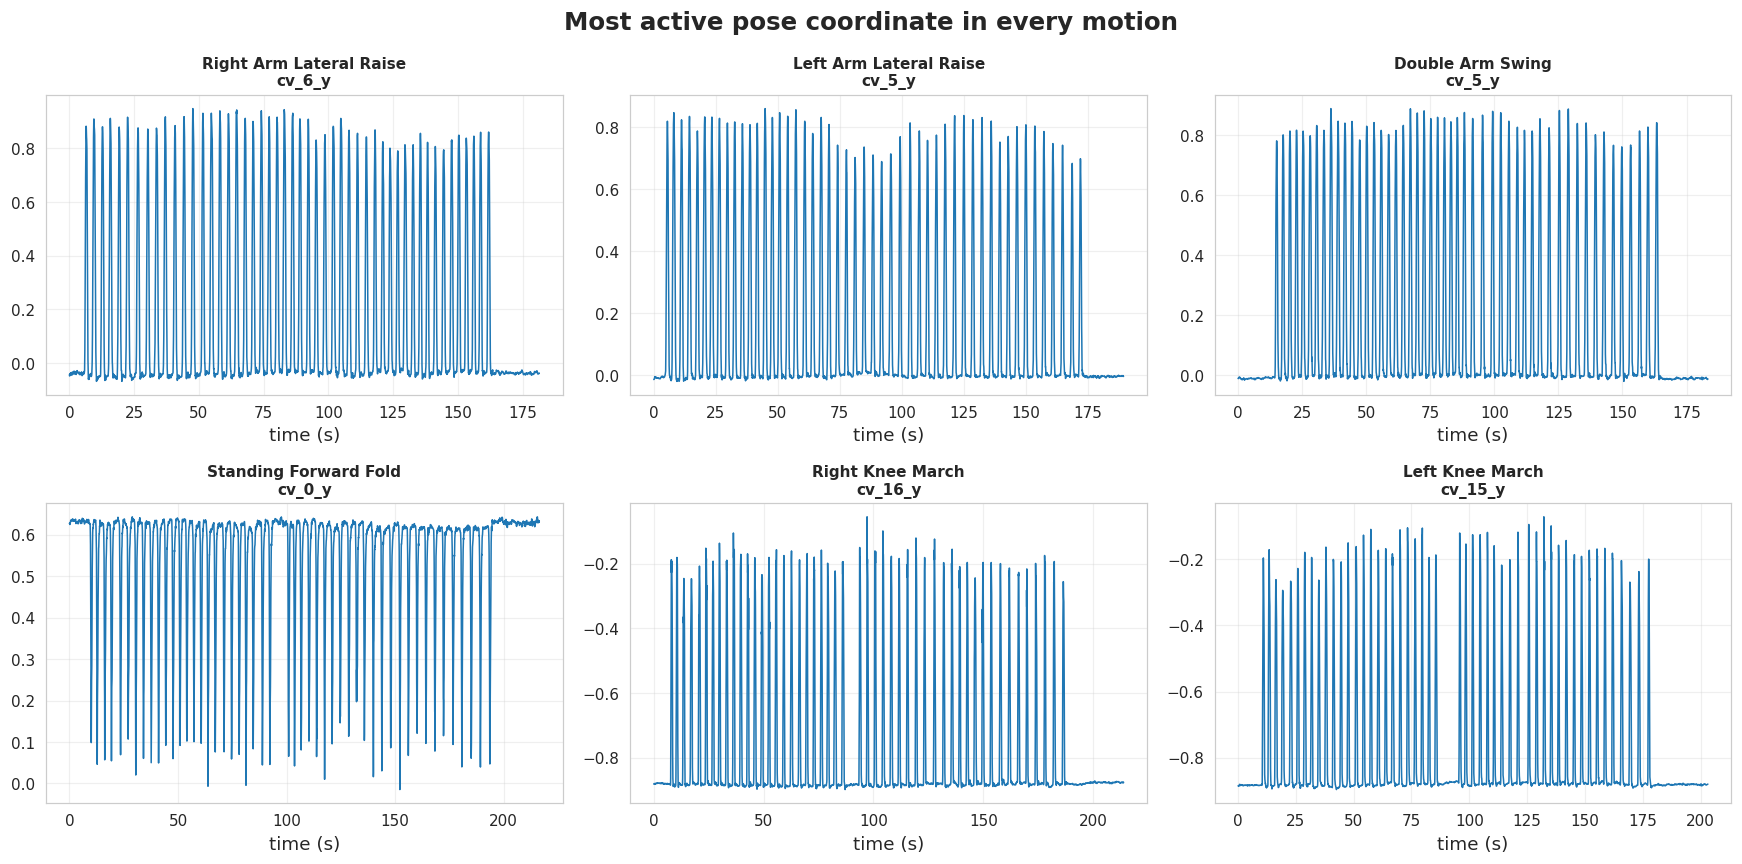

In [8]:
# Quick visual sanity check: the most active pose coordinate of every motion
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (m, d) in zip(axes.ravel(), MOTION_DATA.items()):
    j = int(np.argmax(d["Y_raw"].std(axis=0)))
    tt = d["t"] - d["t"][0]
    ax.plot(tt, d["Y_raw"][:, j], lw=1)
    ax.set_title(f"{m}\n{pose_cols[j]}", fontsize=10)
    ax.set_xlabel("time (s)")
for ax in axes.ravel()[len(MOTION_DATA):]:
    ax.axis("off")
plt.suptitle("Most active pose coordinate in every motion", fontsize=16, fontweight="bold")
plt.tight_layout()
savefig("all_motions_overview.png")
plt.show()

## 4. Model architectures

Identical to the single-motion notebook (MLP, 1D-CNN, GRU, LSTM, Transformer) with Gaussian input noise and
random *sensor dropout* during training only, L2 regularisation, and a skip path from the latest IMU frame
for the recurrent models.

In [10]:
L2 = keras.regularizers.l2(1e-4)

@keras.utils.register_keras_serializable(package="mocap")
class SensorDropout(layers.Layer):
    """Training-only: independently blank each sensor's channels (set to the train mean = 0)."""
    def __init__(self, n_sensors, channels=6, rate=0.05, **kwargs):
        super().__init__(**kwargs)
        self.n_sensors, self.channels, self.rate = n_sensors, channels, rate

    def call(self, x, training=None):
        if not training or self.rate <= 0:
            return x
        shape = tf.shape(x)
        x5 = tf.reshape(x, (shape[0], shape[1], self.n_sensors, self.channels))
        keep = tf.cast(tf.random.uniform((shape[0], 1, self.n_sensors, 1)) >= self.rate, x.dtype)
        return tf.reshape(x5 * keep, shape)

    def compute_output_shape(self, input_shape):
        return input_shape

    def get_config(self):
        cfg = super().get_config()
        cfg.update(n_sensors=self.n_sensors, channels=self.channels, rate=self.rate)
        return cfg


def _inputs(window_size, n_features):
    inp = layers.Input(shape=(window_size, n_features), name="imu_window")
    x = SensorDropout(n_features // 6, 6, SENSOR_DROPOUT)(inp)
    x = layers.GaussianNoise(NOISE_STD)(x)
    return inp, x

def last_step(x):
    return layers.Flatten()(layers.Cropping1D((x.shape[1] - 1, 0))(x))

def build_mlp(window_size, n_features, n_outputs):
    inp, x = _inputs(window_size, n_features)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=L2)(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu", kernel_regularizer=L2)(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_outputs, name="pose_output")(x)
    return keras.Model(inp, out, name="MLP")

def build_cnn1d(window_size, n_features, n_outputs):
    inp, x = _inputs(window_size, n_features)
    x = layers.Conv1D(32, 3, padding="causal", activation="relu", kernel_regularizer=L2)(x)
    x = layers.Conv1D(64, 3, padding="causal", activation="relu", kernel_regularizer=L2)(x)
    x = layers.SpatialDropout1D(0.2)(x)
    x = layers.Concatenate()([layers.GlobalAveragePooling1D()(x), last_step(x)])
    x = layers.Dense(64, activation="relu", kernel_regularizer=L2)(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_outputs, name="pose_output")(x)
    return keras.Model(inp, out, name="CNN1D")

def _recurrent(cell_layer, name):
    def build(window_size, n_features, n_outputs):
        inp, x = _inputs(window_size, n_features)
        r = cell_layer(64)(x)
        r = layers.Dropout(0.3)(r)
        s = layers.Dense(32, activation="relu", kernel_regularizer=L2)(last_step(x))   # skip path
        h = layers.Concatenate()([r, s])
        h = layers.Dense(64, activation="relu", kernel_regularizer=L2)(h)
        h = layers.Dropout(0.2)(h)
        out = layers.Dense(n_outputs, name="pose_output")(h)
        return keras.Model(inp, out, name=name)
    return build

build_gru  = _recurrent(layers.GRU,  "GRU")
build_lstm = _recurrent(layers.LSTM, "LSTM")

@keras.utils.register_keras_serializable(package="mocap")
class PositionalEncoding(layers.Layer):
    def __init__(self, seq_len, d_model, **kwargs):
        super().__init__(**kwargs)
        self.seq_len, self.d_model = seq_len, d_model
        pos = np.arange(seq_len)[:, None]
        i = np.arange(d_model)[None, :]
        angle_rads = pos * (1 / np.power(10000, (2 * (i // 2)) / np.float32(d_model)))
        angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
        angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])
        self.pos_encoding = tf.constant(angle_rads[None, ...], dtype=tf.float32)

    def call(self, x):
        return x + tf.cast(self.pos_encoding, x.dtype)

    def compute_output_shape(self, input_shape):
        return input_shape

    def get_config(self):
        cfg = super().get_config()
        cfg.update(seq_len=self.seq_len, d_model=self.d_model)
        return cfg

def transformer_encoder_block(x, d_model, num_heads, ff_dim, dropout=0.2):
    attn = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)(x, x)
    attn = layers.Dropout(dropout)(attn)
    x = layers.LayerNormalization(epsilon=1e-6)(x + attn)
    ffn = layers.Dense(ff_dim, activation="relu", kernel_regularizer=L2)(x)
    ffn = layers.Dense(d_model, kernel_regularizer=L2)(ffn)
    ffn = layers.Dropout(dropout)(ffn)
    return layers.LayerNormalization(epsilon=1e-6)(x + ffn)

def build_transformer(window_size, n_features, n_outputs,
                      d_model=32, num_heads=2, ff_dim=64, num_blocks=1, dropout=0.2):
    inp, x = _inputs(window_size, n_features)
    x = layers.Dense(d_model)(x)
    x = PositionalEncoding(window_size, d_model)(x)
    for _ in range(num_blocks):
        x = transformer_encoder_block(x, d_model, num_heads, ff_dim, dropout)
    x = layers.Concatenate()([layers.GlobalAveragePooling1D()(x), last_step(x)])
    x = layers.Dense(64, activation="relu", kernel_regularizer=L2)(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(n_outputs, name="pose_output")(x)
    return keras.Model(inp, out, name="Transformer")

MODEL_BUILDERS = {"MLP": build_mlp, "CNN1D": build_cnn1d, "GRU": build_gru,
                  "LSTM": build_lstm, "Transformer": build_transformer}

for name, builder in MODEL_BUILDERS.items():
    m = builder(WINDOW_SIZE, N_FEATURES, N_OUTPUTS)
    print(f"{name:12s} -> {m.count_params():,} parameters")
    del m

MLP          -> 50,099 parameters
CNN1D        -> 20,691 parameters
GRU          -> 28,947 parameters
LSTM         -> 34,835 parameters
Transformer  -> 17,011 parameters


## 5. Training and evaluation helpers

* **Weighted Huber loss** (per-column variance weights, floored) is built from the scaler of whatever dataset
  is being trained (one motion in Part A, all motions in Part C).
* **Seed ensemble**: `n_seeds` models of the same type are averaged. Parameter counts are per member, FPS is for the whole ensemble (batch `predict`, after a warm-up).
* **Metrics**: MAE, MSE, RMSE, **MPJPE** and four R² variants:
  `R2` variance-weighted, `R2 OOS` vs a constant train-mean forecast, `R2 active` (uniform R² over columns whose
  **train** variance is at least `ACTIVE_VAR_FRAC` x the mean column variance, a fixed set per dataset) and `R2 uniform` (reference only).
  Rank models with `MPJPE` and `R2 OOS`.
* **Model selection uses validation MPJPE only.**


In [13]:
def make_weighted_huber(pose_scaler, floor=LOSS_FLOOR, delta=1.0):
    s2 = pose_scaler.scale_ ** 2
    w = floor + (1 - floor) * (s2 / s2.mean())
    W = tf.constant(w / w.mean(), dtype=tf.float32)
    def weighted_huber(y_true, y_pred):
        err  = tf.abs(y_pred - y_true)
        quad = tf.minimum(err, delta)
        lin  = err - quad
        return tf.reduce_mean(W * (0.5 * quad ** 2 + delta * lin), axis=-1)
    return weighted_huber


class EnsembleModel:
    """Averages several Keras models."""
    def __init__(self, members):
        self.members = members

    def predict(self, X, verbose=0, **kwargs):
        preds = [np.asarray(m.predict(X, verbose=0, **kwargs), dtype="float64") for m in self.members]
        return np.mean(preds, axis=0)

    def count_params(self):                       # parameters of ONE member
        return int(self.members[0].count_params())

    @classmethod
    def load(cls, path):
        """Inverse of save(): loads <stem>_member*.keras into an ensemble."""
        stem = path[:-6] if path.endswith(".keras") else path
        files = sorted(glob.glob(f"{stem}_member*.keras"))
        if not files:
            raise FileNotFoundError(f"No ensemble members found for {stem}_member*.keras")
        return cls([keras.models.load_model(f, compile=False) for f in files])

    def save(self, path):
        stem = path[:-6] if path.endswith(".keras") else path
        for i, m in enumerate(self.members):
            m.save(f"{stem}_member{i}.keras")


def train_ensemble(model_name, builder, data, pose_scaler, n_seeds, batch_size, tag,
                   use_ckpt=False, verbose=True):
    """Train n_seeds models on data['train'], validate on data['val']. Returns (EnsembleModel, seed-0 history, seconds)."""
    X_tr, Y_tr = data["train"]; X_va, Y_va = data["val"]
    loss_fn = make_weighted_huber(pose_scaler)
    members, hist0, start = [], None, time.time()
    for k in range(n_seeds):
        tf.keras.backend.clear_session()
        keras.utils.set_random_seed(SEED + k)
        model = builder(WINDOW_SIZE, N_FEATURES, N_OUTPUTS)
        model.compile(optimizer=keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-3),
                      loss=loss_fn, metrics=["mae"])
        cbs = [
            keras.callbacks.EarlyStopping(monitor="val_loss", patience=40, min_delta=1e-4,
                                          restore_best_weights=True, verbose=0),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=12,
                                              min_lr=1e-5, verbose=0),
        ]
        if use_ckpt:
            cbs.append(keras.callbacks.ModelCheckpoint(
                os.path.join(DIR_MODELS, f"{tag}_{model_name}_seed{k}_best.keras"),
                monitor="val_loss", save_best_only=True, verbose=0))
            cbs.append(keras.callbacks.TensorBoard(log_dir=os.path.join(DIR_LOGS, f"{tag}_{model_name}_seed{k}")))
        hist = model.fit(X_tr, Y_tr, validation_data=(X_va, Y_va), epochs=EPOCHS,
                         batch_size=batch_size, callbacks=cbs, verbose=0)
        h = hist.history
        best = int(np.argmin(h["val_loss"]))
        if verbose:
            print(f"    {model_name:11s} seed {k}: {len(h['loss']):3d} epochs | best {best + 1:3d} | "
                  f"train {h['loss'][best]:.4f} | val {h['val_loss'][best]:.4f}")
        members.append(model)
        if k == 0:
            hist0 = {key: [float(v) for v in vals] for key, vals in h.items()}
    return EnsembleModel(members), hist0, time.time() - start


# ---------------------------------------------------------------------------------
# Metrics
# ---------------------------------------------------------------------------------
ACTIVE_VAR_FRAC = 0.10   # a column is "active" if its TRAIN variance >= this x the mean column variance

def active_mask_from(var):
    var = np.asarray(var, dtype="float64")
    return var >= ACTIVE_VAR_FRAC * var.mean()

def mpjpe(y_true, y_pred, n_joints=N_JOINTS):
    yt = y_true.reshape(-1, n_joints, 3); yp = y_pred.reshape(-1, n_joints, 3)
    d = np.linalg.norm(yt - yp, axis=-1)
    return d.mean(), d.mean(axis=0)

def r2_time_series(y_true, y_pred, bench_mean, active_mask):
    sse   = ((y_true - y_pred) ** 2).sum(axis=0)
    sse_b = ((y_true - bench_mean) ** 2).sum(axis=0)          # benchmark: constant train mean
    return dict(
        r2         = r2_score(y_true, y_pred, multioutput="variance_weighted"),
        r2_oos     = 1.0 - sse.sum() / sse_b.sum(),
        r2_active  = r2_score(y_true[:, active_mask], y_pred[:, active_mask]),
        r2_uniform = r2_score(y_true, y_pred, multioutput="uniform_average"),
        n_active   = int(active_mask.sum()))

def compute_metrics(y_true, y_pred, pose_scaler, bench_mean=None, active_mask=None):
    """bench_mean / active_mask default to the scaler's train mean / train-variance mask. Pass a motion's own
    values to get per-motion numbers that are comparable with Part A."""
    bench_mean  = pose_scaler.mean_ if bench_mean is None else bench_mean
    active_mask = active_mask_from(pose_scaler.var_) if active_mask is None else active_mask
    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    r2m  = r2_time_series(y_true, y_pred, bench_mean, active_mask)
    mp, per_joint = mpjpe(y_true, y_pred)
    return dict(mae=mae, mse=mse, rmse=float(np.sqrt(mse)), mpjpe=mp, per_joint_mpjpe=per_joint,
                y_true=y_true, y_pred=y_pred, **r2m)

def predict_orig(model, X, pose_scaler):
    p = np.asarray(model.predict(X, verbose=0), dtype="float64")
    return pose_scaler.inverse_transform(p).astype("float64")

def evaluate_split(model, X, Y_scaled, pose_scaler):
    y_true = pose_scaler.inverse_transform(Y_scaled).astype("float64")
    return compute_metrics(y_true, predict_orig(model, X, pose_scaler), pose_scaler)

def evaluate_all_splits(model, data, pose_scaler):
    """Returns train/val/test metrics, inference time (s) and FPS measured on the test split."""
    tr = evaluate_split(model, *data["train"], pose_scaler)
    va = evaluate_split(model, *data["val"],   pose_scaler)
    X_te, Y_te = data["test"]
    y_pred = predict_orig(model, X_te, pose_scaler)          # also warms the model up
    runs = []
    for _ in range(3):                                         # pure predict timing, median of 3
        t0 = time.perf_counter(); model.predict(X_te, verbose=0); runs.append(time.perf_counter() - t0)
    inf = float(np.median(runs))
    te = compute_metrics(pose_scaler.inverse_transform(Y_te).astype("float64"), y_pred, pose_scaler)
    return tr, va, te, inf, (len(X_te) / inf if inf > 0 else float("nan"))


class LastFrameSklearn:
    """Classical reference model that only sees the LATEST IMU frame of each window."""
    def __init__(self, est): self.est = est
    def fit(self, X, Y): self.est.fit(X[:, -1, :], Y); return self
    def predict(self, X, verbose=0): return self.est.predict(X[:, -1, :])

def make_reference_models():
    return {
        "Ridge (last frame)":      LastFrameSklearn(Ridge(alpha=10)),
        "ExtraTrees (last frame)": LastFrameSklearn(ExtraTreesRegressor(
            n_estimators=300, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=SEED)),
    }

def make_row(scope, model_name, mtype, tr, va, te, n_params, train_time, fps):
    return dict(Motion=scope, Model=model_name, Type=mtype, Params=n_params,
                TrainTime_s=round(train_time, 2), FPS=round(fps, 1),
                Train_MPJPE=tr["mpjpe"], Val_MPJPE=va["mpjpe"],
                Test_MAE=te["mae"], Test_RMSE=te["rmse"], Test_MPJPE=te["mpjpe"],
                Test_R2=te["r2"], Test_R2_OOS=te["r2_oos"], Test_R2_active=te["r2_active"],
                Test_over_Train=te["mpjpe"] / max(tr["mpjpe"], 1e-12))


# ---------------------------------------------------------------------------------
# Windowing (inside each contiguous segment only)
# ---------------------------------------------------------------------------------
def create_sequences(X, Y, window_size=WINDOW_SIZE, stride=STRIDE):
    xs, ys = [], []
    for start in range(0, len(X) - window_size + 1, stride):
        end = start + window_size
        xs.append(X[start:end]); ys.append(Y[end - 1])
    return np.array(xs, dtype="float32"), np.array(ys, dtype="float32")

def split_arrays(X_scaled, Y_scaled, segments):
    parts = {"train": ([], []), "val": ([], []), "test": ([], [])}
    for nm, s, e in segments:
        xs, ys = create_sequences(X_scaled[s:e], Y_scaled[s:e])
        if len(xs):
            parts[nm][0].append(xs); parts[nm][1].append(ys)
    out = {}
    for k, (xl, yl) in parts.items():
        out[k] = (np.concatenate(xl), np.concatenate(yl)) if xl else \
                 (np.empty((0, WINDOW_SIZE, N_FEATURES), "float32"), np.empty((0, N_OUTPUTS), "float32"))
    return out

def train_row_indices(segments):
    return np.concatenate([np.arange(s, e) for nm, s, e in segments if nm == "train"])

## 6. Skeleton / plotting helpers

In [43]:
KEYPOINT_NAMES = ["Head", "Left Shoulder", "Right Shoulder", "Left Elbow", "Right Elbow",
                  "Left Wrist", "Right Wrist", "Left Hip", "Right Hip", "Left Knee", "Right Knee",
                  "Left Ankle", "Right Ankle", "Left Heel", "Right Heel",
                  "Left Foot Index", "Right Foot Index"]

SKELETON_CONNECTIONS = [(1, 2), (1, 3), (3, 5), (2, 4), (4, 6), (1, 7), (2, 8), (7, 8),
                        (7, 9), (9, 11), (11, 13), (13, 15), (8, 10), (10, 12), (12, 14), (14, 16)]

_VIEW_AXES = {"X": (1, 2, "Y", "Z"), "Y": (0, 2, "X", "Z"), "Z": (0, 1, "X", "Y")}

def plot_projection(ax, coords, body_color, view, title=""):
    ix, iy, xl, yl = _VIEW_AXES[view]
    x, y = coords[:, ix], coords[:, iy]
    ax.scatter(x[1:], y[1:], color=body_color, s=40)
    ax.scatter(x[0], y[0], color=body_color, s=80)
    for a, b in SKELETON_CONNECTIONS:
        ax.plot([x[a], x[b]], [y[a], y[b]], color=body_color, linewidth=2)
    sm = (coords[1] + coords[2]) / 2
    ax.plot([x[0], sm[ix]], [y[0], sm[iy]], color=body_color, linewidth=3)
    if title: ax.set_title(title, fontsize=11, weight="bold")
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.axis("equal"); ax.grid(True)

def plot_skeleton_3x3(true_coords, pred_coords, title, fname):
    fig, axes = plt.subplots(3, 3, figsize=(15, 15))
    for row, view in enumerate(["X", "Y", "Z"]):
        plot_projection(axes[row, 0], true_coords, "green", view, f"Ground Truth - {view} View")
        plot_projection(axes[row, 1], pred_coords, "red", view, f"Prediction - {view} View")
        plot_projection(axes[row, 2], true_coords, "green", view)
        plot_projection(axes[row, 2], pred_coords, "red", view, f"Overlay - {view} View")
    plt.suptitle(title, fontsize=18, weight="bold")
    plt.tight_layout(); savefig(fname); plt.show()

# PART A — Per-motion experiments (6 motions)

For every motion the full pipeline of the single-motion notebook is repeated:

`scale (train rows only) -> windows -> train 5 models -> evaluate -> 2 reference baselines -> save`

One summary figure per motion is shown (loss curves, prediction vs ground truth of the most active
coordinate, per-joint MPJPE of the best model). Results are cached in `results/per_motion/`, so if the
session stops you can re-run and it will continue with the motions not yet finished (`RESUME = True`).

In [19]:
def plot_motion_summary(name, histories, results, best_name):
    fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
    for mn, h in histories.items():
        axes[0].plot(h["val_loss"], label=mn)
    axes[0].set_title(f"{name}: validation loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Weighted Huber")
    axes[0].legend(fontsize=8)

    yt, yp = results[best_name]["test"]["y_true"], results[best_name]["test"]["y_pred"]
    j = int(np.argmax(yt.std(axis=0)))
    axes[1].plot(yt[:, j], lw=2, label="Ground truth"); axes[1].plot(yp[:, j], "--", lw=2, label="Predicted")
    for sm in test_seams(MOTION_DATA[name]["segments"]):
        axes[1].axvline(sm - 0.5, color="gray", linestyle=":", lw=1)
    axes[1].set_title(f"{best_name}: {pose_cols[j]} (test, dotted = block seam)"); axes[1].set_xlabel("Test window"); axes[1].legend()

    axes[2].bar(range(N_JOINTS), results[best_name]["test"]["per_joint_mpjpe"], color="cornflowerblue")
    axes[2].set_xticks(range(N_JOINTS)); axes[2].set_xticklabels(KEYPOINT_NAMES, rotation=70, ha="right", fontsize=8)
    axes[2].set_title(f"{best_name}: per-joint MPJPE (test)")
    plt.suptitle(f"Motion: {name}", fontsize=15, fontweight="bold")
    plt.tight_layout(); savefig(f"motion_{safe_name(name)}_summary.png"); plt.show()


def run_motion(name):
    cache = os.path.join(DIR_PM, f"{safe_name(name)}_{CONFIG_TAG}_summary.csv")
    if RESUME and os.path.exists(cache):
        print(f"[{name}] cached -> {cache} (skipping training)")
        return pd.read_csv(cache)

    md_ = MOTION_DATA[name]
    tr_rows = train_row_indices(md_["segments"])
    imu_sc, pose_sc = fit_scalers(md_["X_raw"][tr_rows], md_["Y_raw"][tr_rows])
    joblib.dump(imu_sc,  os.path.join(DIR_SCALERS, f"{safe_name(name)}_imu_scaler.joblib"))
    joblib.dump(pose_sc, os.path.join(DIR_SCALERS, f"{safe_name(name)}_pose_scaler.joblib"))

    data = split_arrays(scale_imu(imu_sc, md_["X_raw"]),
                        pose_sc.transform(md_["Y_raw"]).astype("float32"), md_["segments"])
    print(f"[{name}] windows -> train {len(data['train'][0])} | val {len(data['val'][0])} | test {len(data['test'][0])}")

    results, histories, ensembles, rows = {}, {}, {}, []
    for mn, builder in MODEL_BUILDERS.items():
        ens, hist, secs = train_ensemble(mn, builder, data, pose_sc, N_SEEDS_MOTION, BATCH_SIZE, safe_name(name))
        tr, va, te, inf, fps = evaluate_all_splits(ens, data, pose_sc)
        results[mn] = dict(train=tr, val=va, test=te)
        histories[mn], ensembles[mn] = hist, ens
        rows.append(make_row(name, mn, "deep", tr, va, te, ens.count_params(), secs, fps))

    for rn, rm in make_reference_models().items():
        t0 = time.time(); rm.fit(*[data["train"][0], data["train"][1]]); secs = time.time() - t0
        tr, va, te, inf, fps = evaluate_all_splits(rm, data, pose_sc)
        rows.append(make_row(name, rn, "reference", tr, va, te, 0, secs, fps))

    rows_df = pd.DataFrame(rows)
    rows_df.to_csv(cache, index=False)

    deep_df = rows_df[rows_df.Type == "deep"]
    best_name = deep_df.loc[deep_df.Val_MPJPE.idxmin(), "Model"]      # selected on VALIDATION MPJPE
    ensembles[best_name].save(os.path.join(DIR_MODELS, f"{safe_name(name)}_best_{best_name}.keras"))
    with open(os.path.join(DIR_PM, f"{safe_name(name)}_history.json"), "w") as f:
        json.dump(histories, f)
    np.save(os.path.join(DIR_PM, f"{safe_name(name)}_y_pred_test_{best_name}.npy"), results[best_name]["test"]["y_pred"])

    print(f"[{name}] best deep model (by val MPJPE): {best_name} | Test MPJPE "
          f"{deep_df.loc[deep_df.Val_MPJPE.idxmin(), 'Test_MPJPE']:.5f}")
    plot_motion_summary(name, histories, results, best_name)
    return rows_df

### Run all 6 motions

This is the long-running cell. Progress is printed per motion; each finished motion is cached to disk.


MOTION 1/6: Right Arm Lateral Raise
[Right Arm Lateral Raise] windows -> train 2348 | val 546 | test 558


I0000 00:00:1792657655.922697     163 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


    MLP         seed 0: 261 epochs | best 221 | train 0.0482 | val 0.0399
    MLP         seed 1: 205 epochs | best 197 | train 0.0488 | val 0.0394
    MLP         seed 2: 243 epochs | best 203 | train 0.0486 | val 0.0395
    CNN1D       seed 0: 177 epochs | best 160 | train 0.0484 | val 0.0408
    CNN1D       seed 1: 229 epochs | best 190 | train 0.0494 | val 0.0401
    CNN1D       seed 2: 190 epochs | best 156 | train 0.0500 | val 0.0404
    GRU         seed 0: 140 epochs | best 100 | train 0.0412 | val 0.0389
    GRU         seed 1: 136 epochs | best 117 | train 0.0388 | val 0.0389
    GRU         seed 2: 142 epochs | best 102 | train 0.0407 | val 0.0389
    LSTM        seed 0: 111 epochs | best 100 | train 0.0380 | val 0.0375
    LSTM        seed 1: 153 epochs | best 117 | train 0.0357 | val 0.0379
    LSTM        seed 2: 148 epochs | best 142 | train 0.0359 | val 0.0385
    Transformer seed 0: 177 epochs | best 137 | train 0.0387 | val 0.0391
    Transformer seed 1: 156 epochs | b

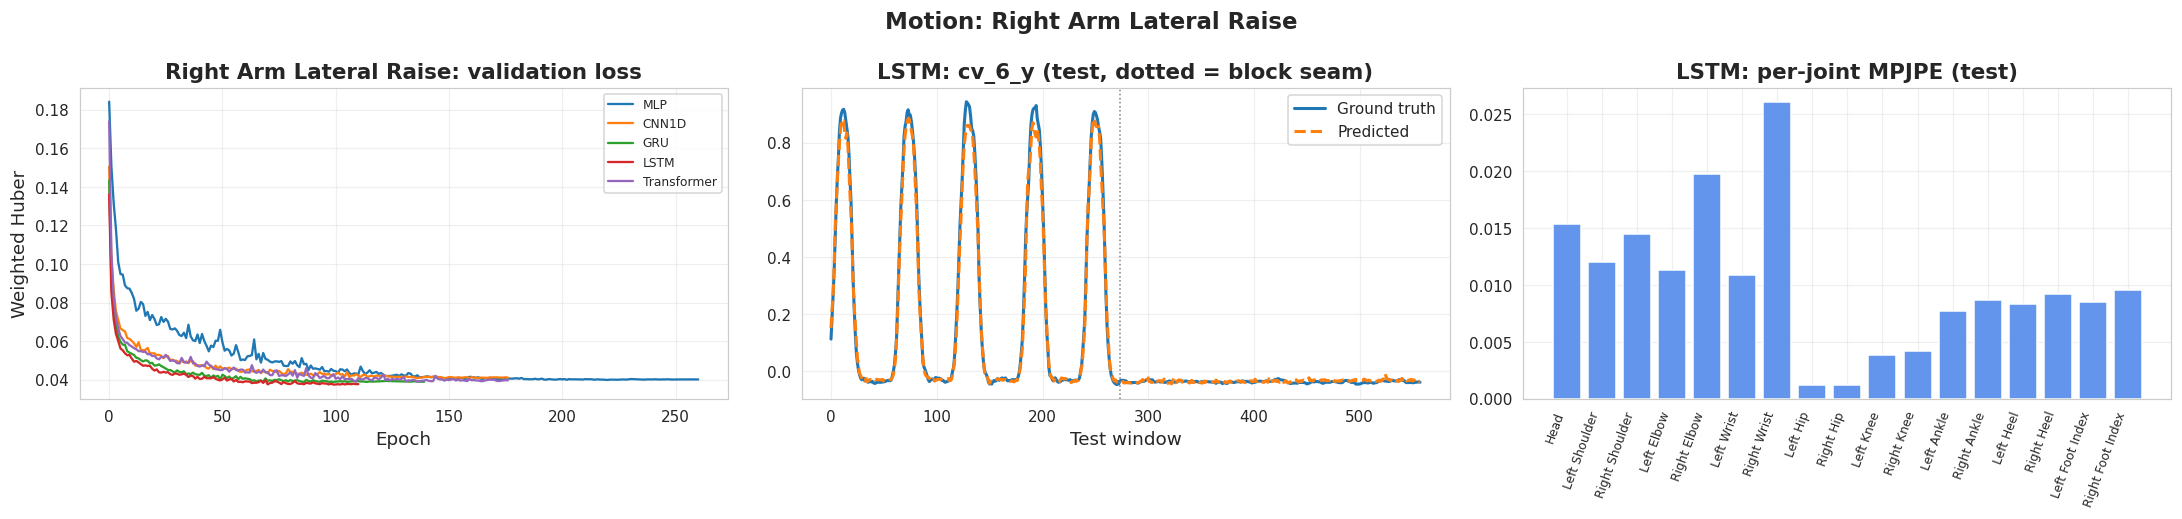

-- elapsed so far: 13.6 min

MOTION 2/6: Left Arm Lateral Raise
[Left Arm Lateral Raise] windows -> train 2454 | val 573 | test 584
    MLP         seed 0: 206 epochs | best 166 | train 0.0577 | val 0.0529
    MLP         seed 1: 231 epochs | best 191 | train 0.0570 | val 0.0529
    MLP         seed 2: 173 epochs | best 133 | train 0.0605 | val 0.0533
    CNN1D       seed 0: 192 epochs | best 152 | train 0.0577 | val 0.0530
    CNN1D       seed 1:  97 epochs | best  57 | train 0.0645 | val 0.0546
    CNN1D       seed 2: 163 epochs | best 142 | train 0.0567 | val 0.0536
    GRU         seed 0:  98 epochs | best  74 | train 0.0504 | val 0.0526
    GRU         seed 1: 130 epochs | best  97 | train 0.0475 | val 0.0527
    GRU         seed 2: 119 epochs | best  79 | train 0.0488 | val 0.0518
    LSTM        seed 0:  76 epochs | best  52 | train 0.0505 | val 0.0534
    LSTM        seed 1: 121 epochs | best  81 | train 0.0467 | val 0.0529
    LSTM        seed 2:  87 epochs | best  47 | train 

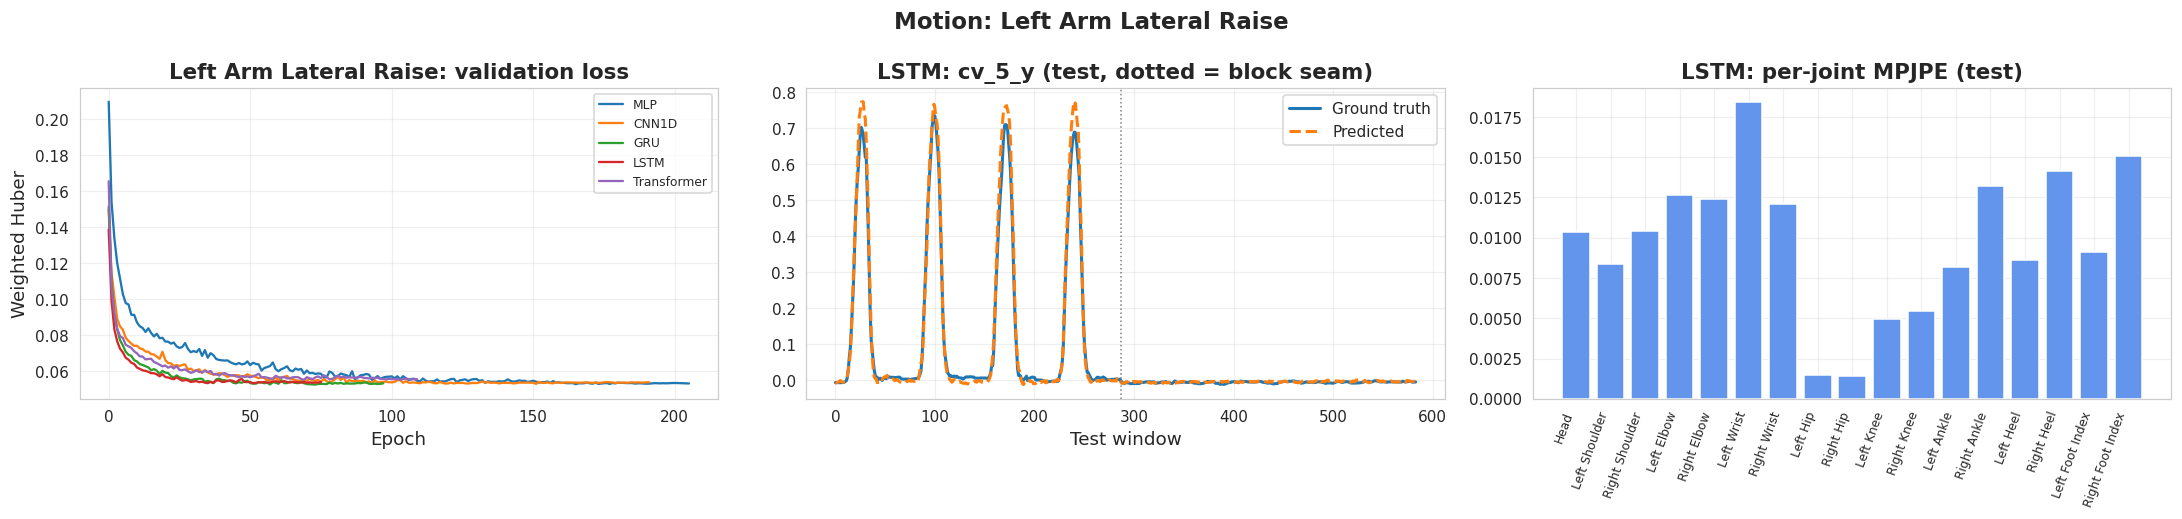

-- elapsed so far: 24.9 min

MOTION 3/6: Double Arm Swing
[Double Arm Swing] windows -> train 2372 | val 554 | test 564
    MLP         seed 0: 223 epochs | best 183 | train 0.0524 | val 0.0451
    MLP         seed 1: 203 epochs | best 174 | train 0.0531 | val 0.0448
    MLP         seed 2: 162 epochs | best 158 | train 0.0463 | val 0.0432
    CNN1D       seed 0: 136 epochs | best  96 | train 0.0486 | val 0.0426
    CNN1D       seed 1: 139 epochs | best 127 | train 0.0479 | val 0.0411
    CNN1D       seed 2: 150 epochs | best 110 | train 0.0473 | val 0.0416
    GRU         seed 0: 117 epochs | best  99 | train 0.0406 | val 0.0403
    GRU         seed 1:  83 epochs | best  43 | train 0.0477 | val 0.0408
    GRU         seed 2: 105 epochs | best  65 | train 0.0416 | val 0.0386
    LSTM        seed 0:  99 epochs | best  59 | train 0.0409 | val 0.0393
    LSTM        seed 1:  89 epochs | best  49 | train 0.0438 | val 0.0408
    LSTM        seed 2:  97 epochs | best  69 | train 0.0389 | val

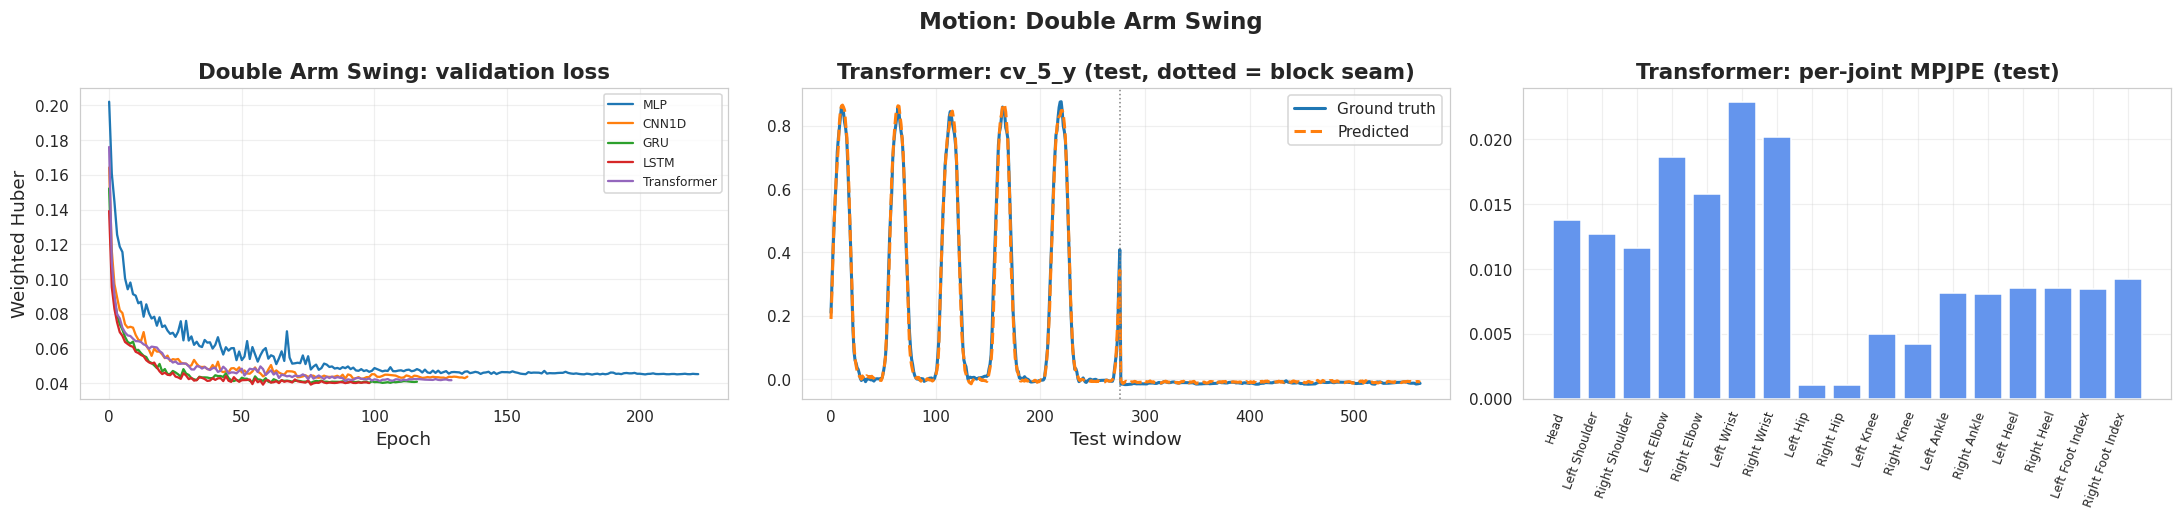

-- elapsed so far: 35.9 min

MOTION 4/6: Standing Forward Fold
[Standing Forward Fold] windows -> train 2812 | val 664 | test 674
    MLP         seed 0: 138 epochs | best  98 | train 0.0724 | val 0.0575
    MLP         seed 1: 197 epochs | best 157 | train 0.0650 | val 0.0537
    MLP         seed 2: 164 epochs | best 139 | train 0.0690 | val 0.0566
    CNN1D       seed 0: 145 epochs | best 129 | train 0.0663 | val 0.0542
    CNN1D       seed 1: 122 epochs | best  82 | train 0.0678 | val 0.0543
    CNN1D       seed 2: 171 epochs | best 131 | train 0.0670 | val 0.0520
    GRU         seed 0: 141 epochs | best 101 | train 0.0512 | val 0.0476
    GRU         seed 1: 131 epochs | best  91 | train 0.0520 | val 0.0473
    GRU         seed 2: 140 epochs | best 122 | train 0.0519 | val 0.0501
    LSTM        seed 0:  96 epochs | best  86 | train 0.0536 | val 0.0504
    LSTM        seed 1: 130 epochs | best  90 | train 0.0511 | val 0.0479
    LSTM        seed 2:  94 epochs | best  54 | train 0.

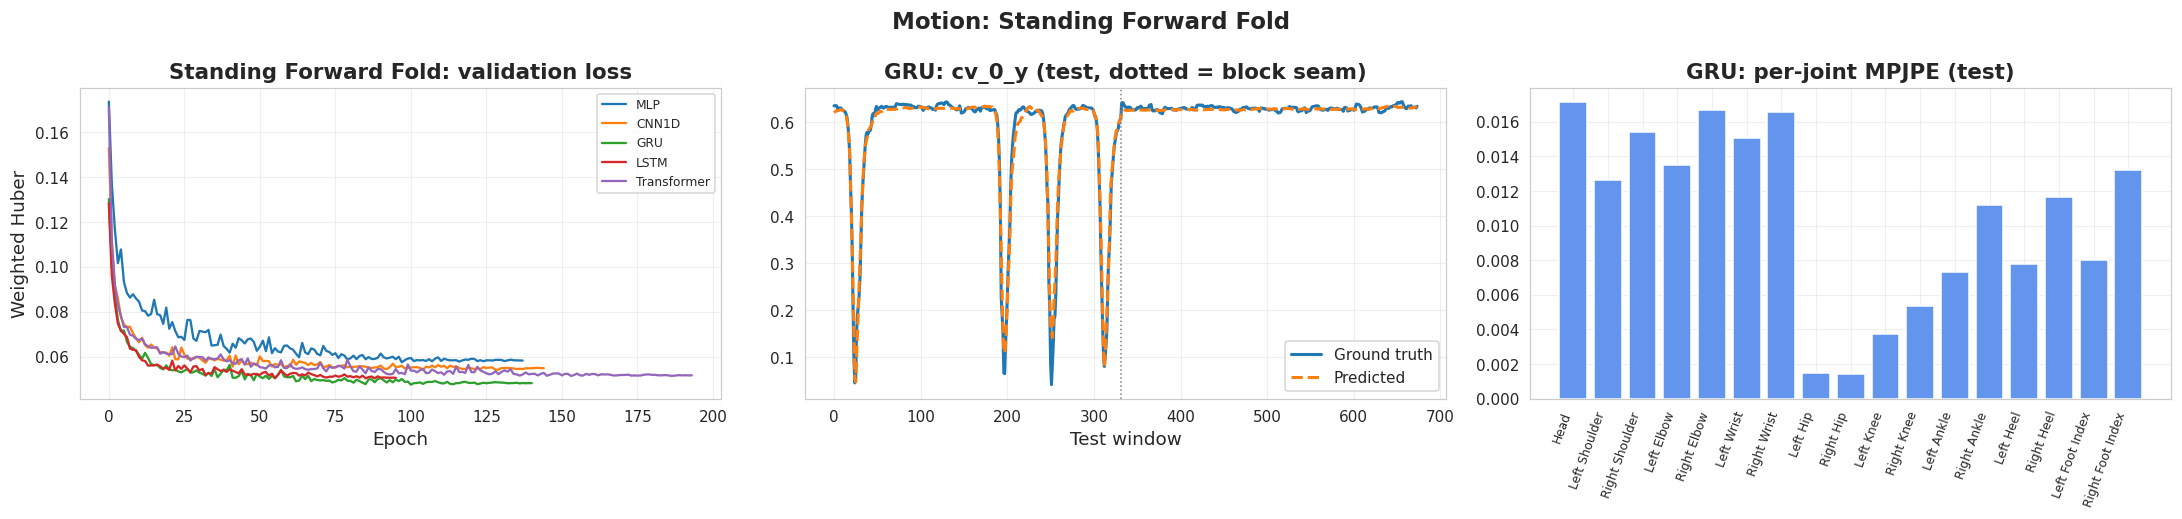

-- elapsed so far: 48.8 min

MOTION 5/6: Right Knee March
[Right Knee March] windows -> train 2780 | val 654 | test 666
    MLP         seed 0: 184 epochs | best 144 | train 0.0453 | val 0.0393
    MLP         seed 1: 169 epochs | best 129 | train 0.0431 | val 0.0395
    MLP         seed 2: 231 epochs | best 191 | train 0.0454 | val 0.0402
    CNN1D       seed 0: 147 epochs | best 147 | train 0.0422 | val 0.0399
    CNN1D       seed 1: 160 epochs | best 153 | train 0.0415 | val 0.0396
    CNN1D       seed 2: 144 epochs | best 104 | train 0.0414 | val 0.0410
    GRU         seed 0:  93 epochs | best  53 | train 0.0373 | val 0.0379
    GRU         seed 1: 138 epochs | best  98 | train 0.0324 | val 0.0368
    GRU         seed 2: 118 epochs | best  78 | train 0.0335 | val 0.0368
    LSTM        seed 0: 124 epochs | best  84 | train 0.0305 | val 0.0376
    LSTM        seed 1: 147 epochs | best 107 | train 0.0310 | val 0.0387
    LSTM        seed 2: 122 epochs | best 103 | train 0.0296 | val

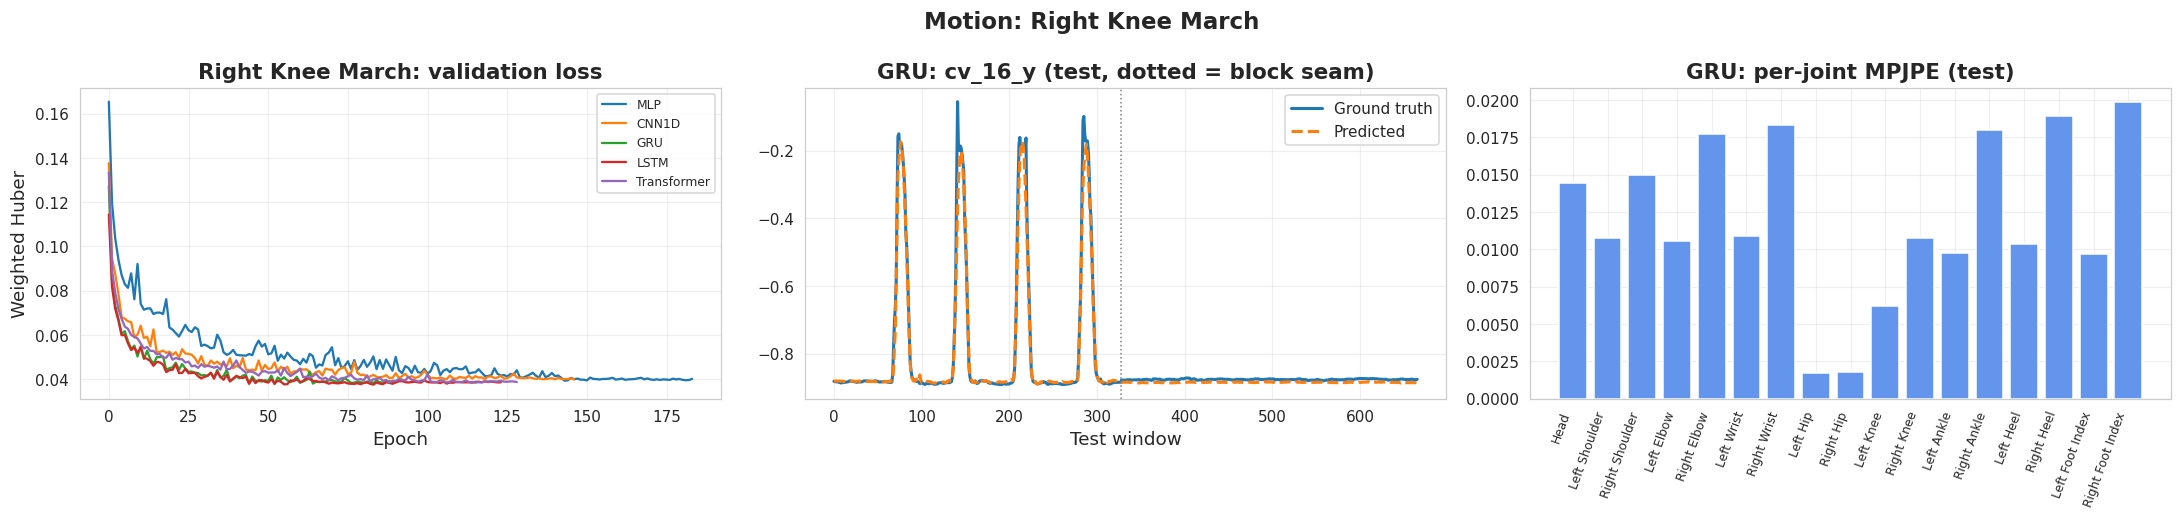

-- elapsed so far: 62.0 min

MOTION 6/6: Left Knee March
[Left Knee March] windows -> train 2638 | val 619 | test 630
    MLP         seed 0: 223 epochs | best 183 | train 0.0417 | val 0.0453
    MLP         seed 1: 236 epochs | best 196 | train 0.0433 | val 0.0449
    MLP         seed 2: 183 epochs | best 170 | train 0.0423 | val 0.0456
    CNN1D       seed 0: 138 epochs | best  98 | train 0.0431 | val 0.0456
    CNN1D       seed 1: 145 epochs | best 105 | train 0.0414 | val 0.0459
    CNN1D       seed 2: 163 epochs | best 123 | train 0.0416 | val 0.0451
    GRU         seed 0: 148 epochs | best 108 | train 0.0304 | val 0.0409
    GRU         seed 1: 148 epochs | best 108 | train 0.0314 | val 0.0395
    GRU         seed 2: 171 epochs | best 132 | train 0.0311 | val 0.0402
    LSTM        seed 0: 112 epochs | best  72 | train 0.0321 | val 0.0404
    LSTM        seed 1: 148 epochs | best 108 | train 0.0314 | val 0.0398
    LSTM        seed 2: 129 epochs | best 107 | train 0.0312 | val 0

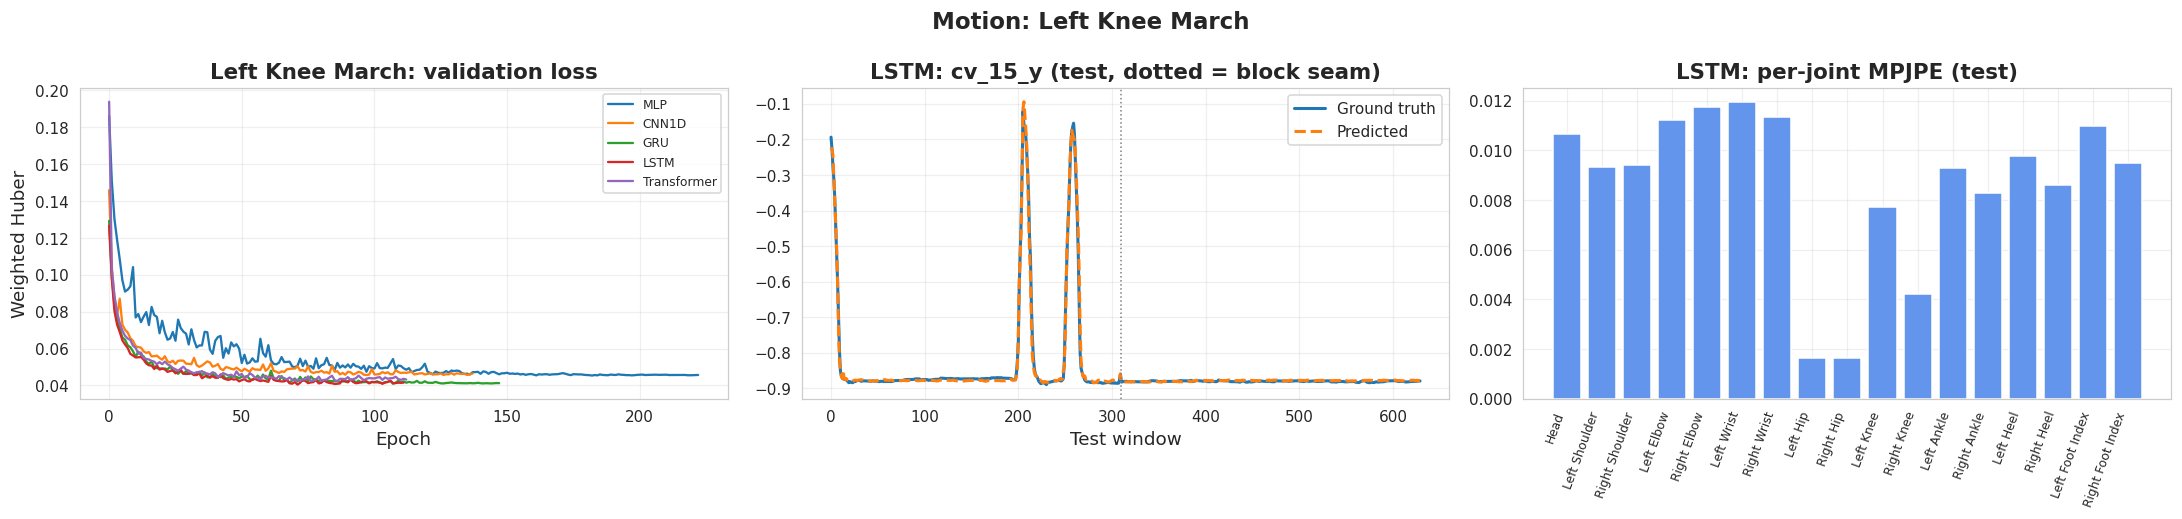

-- elapsed so far: 75.7 min

Part A finished: 6 motions x 7 models.


In [20]:
ALL_ROWS = []
t_start = time.time()
for i, m in enumerate(MOTIONS, 1):
    print("\n" + "=" * 90)
    print(f"MOTION {i}/{len(MOTIONS)}: {m}")
    print("=" * 90)
    ALL_ROWS.append(run_motion(m))
    print(f"-- elapsed so far: {(time.time() - t_start) / 60:.1f} min")

summary_df = pd.concat(ALL_ROWS, ignore_index=True)
summary_df["Motion"] = pd.Categorical(summary_df["Motion"], categories=MOTIONS, ordered=True)
summary_df = summary_df.sort_values(["Motion", "Type", "Test_MPJPE"]).reset_index(drop=True)
summary_df.to_csv(os.path.join(DIR_RESULTS, "all_motions_all_models.csv"), index=False)
print(f"\nPart A finished: {summary_df.Motion.nunique()} motions x {summary_df.groupby('Motion').size().iloc[0]} models.")

# PART B — Summary of all motion results

Everything below is computed from the table `summary_df` produced in Part A (also saved as
`results/all_motions_all_models.csv`). Metrics are on the **test split in original units**.

In [21]:
# TABLE 1 — every motion x every model
cols = ["Motion", "Model", "Type", "Params", "TrainTime_s", "FPS", "Train_MPJPE", "Val_MPJPE",
        "Test_MAE", "Test_RMSE", "Test_MPJPE", "Test_R2", "Test_R2_OOS", "Test_R2_active", "Test_over_Train"]
table1 = summary_df[cols].copy()
print("TABLE 1: ALL MOTIONS x ALL MODELS (test split)")
display(table1.style.format({c: "{:.5f}" for c in ["Train_MPJPE", "Val_MPJPE", "Test_MAE", "Test_RMSE",
                                                  "Test_MPJPE", "Test_R2", "Test_R2_OOS", "Test_R2_active"]}
                            | {"Test_over_Train": "{:.2f}", "Params": "{:,}"})
        .hide(axis="index"))

TABLE 1: ALL MOTIONS x ALL MODELS (test split)


Motion,Model,Type,Params,TrainTime_s,FPS,Train_MPJPE,Val_MPJPE,Test_MAE,Test_RMSE,Test_MPJPE,Test_R2,Test_R2_OOS,Test_R2_active,Test_over_Train
Right Arm Lateral Raise,LSTM,deep,"34,835",158.380000,1603.200000,0.00784,0.01092,0.00485,0.00850,0.01014,0.97544,0.97697,0.87596,1.29
Right Arm Lateral Raise,GRU,deep,"28,947",158.230000,1509.900000,0.00818,0.01122,0.00486,0.00852,0.01022,0.97529,0.97684,0.87829,1.25
Right Arm Lateral Raise,CNN1D,deep,"20,691",147.320000,1685.300000,0.00882,0.01128,0.00500,0.00850,0.01042,0.97542,0.97696,0.87914,1.18
Right Arm Lateral Raise,Transformer,deep,"17,011",162.380000,1631.900000,0.00827,0.01103,0.00497,0.00903,0.01044,0.97225,0.97399,0.86882,1.26
Right Arm Lateral Raise,MLP,deep,"50,099",161.040000,1712.100000,0.00851,0.01117,0.00520,0.00884,0.01077,0.97341,0.97508,0.86758,1.27
Right Arm Lateral Raise,ExtraTrees (last frame),reference,0,1.490000,4413.100000,0.00810,0.01234,0.00497,0.00877,0.01037,0.97385,0.97549,0.89008,1.28
Right Arm Lateral Raise,Ridge (last frame),reference,0,0.090000,37238.300000,0.01675,0.01744,0.00748,0.01581,0.01528,0.91501,0.92033,0.78588,0.91
Left Arm Lateral Raise,CNN1D,deep,"20,691",128.560000,1698.800000,0.00881,0.01083,0.00449,0.00769,0.00957,0.95774,0.96801,0.41598,1.09
Left Arm Lateral Raise,MLP,deep,"50,099",153.180000,1612.800000,0.00840,0.01089,0.00453,0.00771,0.00969,0.95750,0.96783,0.42671,1.15
Left Arm Lateral Raise,GRU,deep,"28,947",133.310000,1661.000000,0.00833,0.01082,0.00457,0.00788,0.00974,0.95556,0.96636,0.41938,1.17


In [27]:
# TABLE 2: best deep model per motion, selected on VALIDATION MPJPE (test is only reported)
deep = summary_df[summary_df.Type == "deep"].copy()
deep["Motion"] = deep["Motion"].astype(str)
best_idx = deep.groupby("Motion")["Val_MPJPE"].idxmin()
table2 = deep.loc[best_idx].set_index("Motion").loc[MOTIONS].reset_index()
ref = summary_df[summary_df.Type == "reference"].assign(Motion=lambda d: d.Motion.astype(str))
ref_best = ref.loc[ref.groupby("Motion")["Val_MPJPE"].idxmin()].set_index("Motion")["Test_MPJPE"].rename("Best_reference_MPJPE")
table2 = table2.merge(ref_best, on="Motion", how="left")
table2["Beats_reference"] = table2["Test_MPJPE"] < table2["Best_reference_MPJPE"]
table2["Group"] = table2["Motion"].map(lambda m: MOTION_INFO[m]["Group"])
table2 = table2[["Motion", "Group", "Model", "Val_MPJPE", "Test_MAE", "Test_RMSE", "Test_MPJPE", "Test_R2", "Test_R2_OOS",
                 "Test_R2_active", "Best_reference_MPJPE", "Beats_reference", "FPS", "Params"]]
table2.to_csv(os.path.join(DIR_RESULTS, "best_model_per_motion.csv"), index=False)
print("TABLE 2: BEST DEEP MODEL PER MOTION (selected on validation MPJPE)")
display(table2.style.format({c: "{:.5f}" for c in ["Test_MAE", "Test_RMSE", "Test_MPJPE", "Test_R2",
                                                  "Test_R2_OOS", "Test_R2_active", "Best_reference_MPJPE"]}
                            | {"Params": "{:,}"}).hide(axis="index"))
print("\nMean over the 6 motions of the best model: "
      f"MPJPE {table2.Test_MPJPE.mean():.5f} | R2 OOS {table2.Test_R2_OOS.mean():.4f} | R2 {table2.Test_R2.mean():.4f}")
print("\nBest-model results averaged by body group (arm / trunk / leg):")
display(table2.groupby("Group")[["Test_MPJPE", "Test_R2_OOS", "Test_R2"]].mean()
        .style.format("{:.5f}"))

TABLE 2: BEST DEEP MODEL PER MOTION (selected on validation MPJPE)


Motion,Group,Model,Val_MPJPE,Test_MAE,Test_RMSE,Test_MPJPE,Test_R2,Test_R2_OOS,Test_R2_active,Best_reference_MPJPE,Beats_reference,FPS,Params
Right Arm Lateral Raise,Arm,LSTM,0.010921,0.00485,0.00850,0.01014,0.97544,0.97697,0.87596,0.01037,True,1603.200000,"34,835"
Left Arm Lateral Raise,Arm,LSTM,0.010705,0.00459,0.00795,0.00979,0.95474,0.96575,0.37790,0.00975,False,1663.700000,"34,835"
Double Arm Swing,Arm,Transformer,0.012194,0.00486,0.00885,0.01046,0.98279,0.98386,0.83400,0.01002,False,1742.200000,"17,011"
Standing Forward Fold,Trunk,GRU,0.011351,0.00490,0.00876,0.01047,0.91663,0.92568,0.64756,0.01093,True,1754.400000,"28,947"
Right Knee March,Leg,GRU,0.013367,0.00598,0.01102,0.01206,0.96461,0.96831,0.89682,0.01198,False,1820.800000,"28,947"
Left Knee March,Leg,LSTM,0.015285,0.00421,0.00732,0.00866,0.97337,0.98030,0.85825,0.00823,False,1749.100000,"34,835"



Mean over the 6 motions of the best model: MPJPE 0.01026 | R2 OOS 0.9668 | R2 0.9613

Best-model results averaged by body group (arm / trunk / leg):


,Test_MPJPE,Test_R2_OOS,Test_R2
Group,,,
Arm,0.01013,0.97553,0.97099
Leg,0.01036,0.97431,0.96899
Trunk,0.01047,0.92568,0.91663


In [28]:
# TABLE 3 — Test MPJPE matrix (motion x model), lower is better
mpjpe_matrix = summary_df.assign(Motion=summary_df.Motion.astype(str)).pivot(index="Motion", columns="Model", values="Test_MPJPE").loc[MOTIONS]
deep_cols = list(MODEL_BUILDERS)
mpjpe_matrix = mpjpe_matrix[deep_cols + [c for c in mpjpe_matrix.columns if c not in deep_cols]]
mpjpe_matrix.to_csv(os.path.join(DIR_RESULTS, "mpjpe_matrix_motion_x_model.csv"))
print("TABLE 3: TEST MPJPE (rows = motions, columns = models; green = best in row)")
display(mpjpe_matrix.style.format("{:.5f}").highlight_min(axis=1, color="lightgreen"))

r2_matrix = summary_df.assign(Motion=summary_df.Motion.astype(str)).pivot(index="Motion", columns="Model", values="Test_R2_OOS").loc[MOTIONS]
r2_matrix = r2_matrix[mpjpe_matrix.columns]
r2_matrix.to_csv(os.path.join(DIR_RESULTS, "r2_oos_matrix_motion_x_model.csv"))
print("\nTABLE 3b: TEST R2 OOS vs train-mean forecast (higher is better; > 0 beats the benchmark)")
display(r2_matrix.style.format("{:.4f}").highlight_max(axis=1, color="lightgreen"))

TABLE 3: TEST MPJPE (rows = motions, columns = models; green = best in row)


Model,MLP,CNN1D,GRU,LSTM,Transformer,ExtraTrees (last frame),Ridge (last frame)
Motion,,,,,,,
Right Arm Lateral Raise,0.01077,0.01042,0.01022,0.01014,0.01044,0.01037,0.01528
Left Arm Lateral Raise,0.00969,0.00957,0.00974,0.00979,0.01045,0.00975,0.01188
Double Arm Swing,0.01088,0.01038,0.01043,0.01022,0.01046,0.01002,0.01824
Standing Forward Fold,0.01051,0.01029,0.01047,0.01047,0.01043,0.01093,0.01290
Right Knee March,0.01189,0.01195,0.01206,0.01238,0.01127,0.01198,0.02225
Left Knee March,0.00844,0.00853,0.00879,0.00866,0.00829,0.00823,0.01424



TABLE 3b: TEST R2 OOS vs train-mean forecast (higher is better; > 0 beats the benchmark)


Model,MLP,CNN1D,GRU,LSTM,Transformer,ExtraTrees (last frame),Ridge (last frame)
Motion,,,,,,,
Right Arm Lateral Raise,0.9751,0.9770,0.9768,0.9770,0.9740,0.9755,0.9203
Left Arm Lateral Raise,0.9678,0.9680,0.9664,0.9657,0.9606,0.9671,0.9416
Double Arm Swing,0.9822,0.9839,0.9836,0.9843,0.9839,0.9847,0.9180
Standing Forward Fold,0.9244,0.9272,0.9257,0.9263,0.9259,0.9184,0.8609
Right Knee March,0.9694,0.9698,0.9683,0.9676,0.9700,0.9647,0.8817
Left Knee March,0.9791,0.9781,0.9785,0.9803,0.9811,0.9801,0.9316


In [29]:
# TABLE 4 — average performance of every model across the 6 motions
rank_mat = mpjpe_matrix[deep_cols].rank(axis=1, method="min")
avg = (summary_df.assign(Motion=summary_df.Motion.astype(str)).groupby("Model")
       .agg(Mean_MAE=("Test_MAE", "mean"), Mean_RMSE=("Test_RMSE", "mean"), Mean_MPJPE=("Test_MPJPE", "mean"),
            Std_MPJPE=("Test_MPJPE", "std"), Mean_R2=("Test_R2", "mean"), Mean_R2_OOS=("Test_R2_OOS", "mean"),
            Mean_R2_active=("Test_R2_active", "mean"), Mean_FPS=("FPS", "mean")))
avg["Mean_rank_among_deep"] = rank_mat.mean(axis=0)
avg["Wins (best of 5 deep)"] = (rank_mat == 1).sum(axis=0)
avg = avg.sort_values("Mean_MPJPE")
avg.to_csv(os.path.join(DIR_RESULTS, "model_average_over_motions.csv"))
print("TABLE 4: AVERAGE OVER 6 MOTIONS")
display(avg.style.format({"Mean_MAE": "{:.5f}", "Mean_RMSE": "{:.5f}", "Mean_MPJPE": "{:.5f}", "Std_MPJPE": "{:.5f}",
                          "Mean_R2": "{:.4f}", "Mean_R2_OOS": "{:.4f}", "Mean_R2_active": "{:.4f}",
                          "Mean_FPS": "{:.1f}", "Mean_rank_among_deep": "{:.2f}"}))

TABLE 4: AVERAGE OVER 6 MOTIONS


,Mean_MAE,Mean_RMSE,Mean_MPJPE,Std_MPJPE,Mean_R2,Mean_R2_OOS,Mean_R2_active,Mean_FPS,Mean_rank_among_deep,Wins (best of 5 deep)
Model,,,,,,,,,,
CNN1D,0.00488,0.00870,0.01019,0.00113,0.9618,0.9673,0.7588,1747.8,2.17,2.000000
ExtraTrees (last frame),0.00486,0.00889,0.01021,0.00125,0.9594,0.9651,0.7575,4820.9,nan,nan
Transformer,0.00486,0.00884,0.01022,0.00100,0.9601,0.9659,0.7506,1776.1,2.83,2.000000
LSTM,0.00491,0.00873,0.01028,0.00121,0.9613,0.9669,0.7480,1707.4,3.00,2.000000
GRU,0.00491,0.00880,0.01028,0.00107,0.9609,0.9665,0.7552,1681.0,3.50,0.000000
MLP,0.00498,0.00884,0.01036,0.00118,0.9608,0.9663,0.7565,1784.2,3.50,0.000000
Ridge (last frame),0.00765,0.01551,0.01580,0.00385,0.8950,0.9090,0.6497,692866.2,nan,nan


Saved figure -> figures/summary_mpjpe_all_motions.png


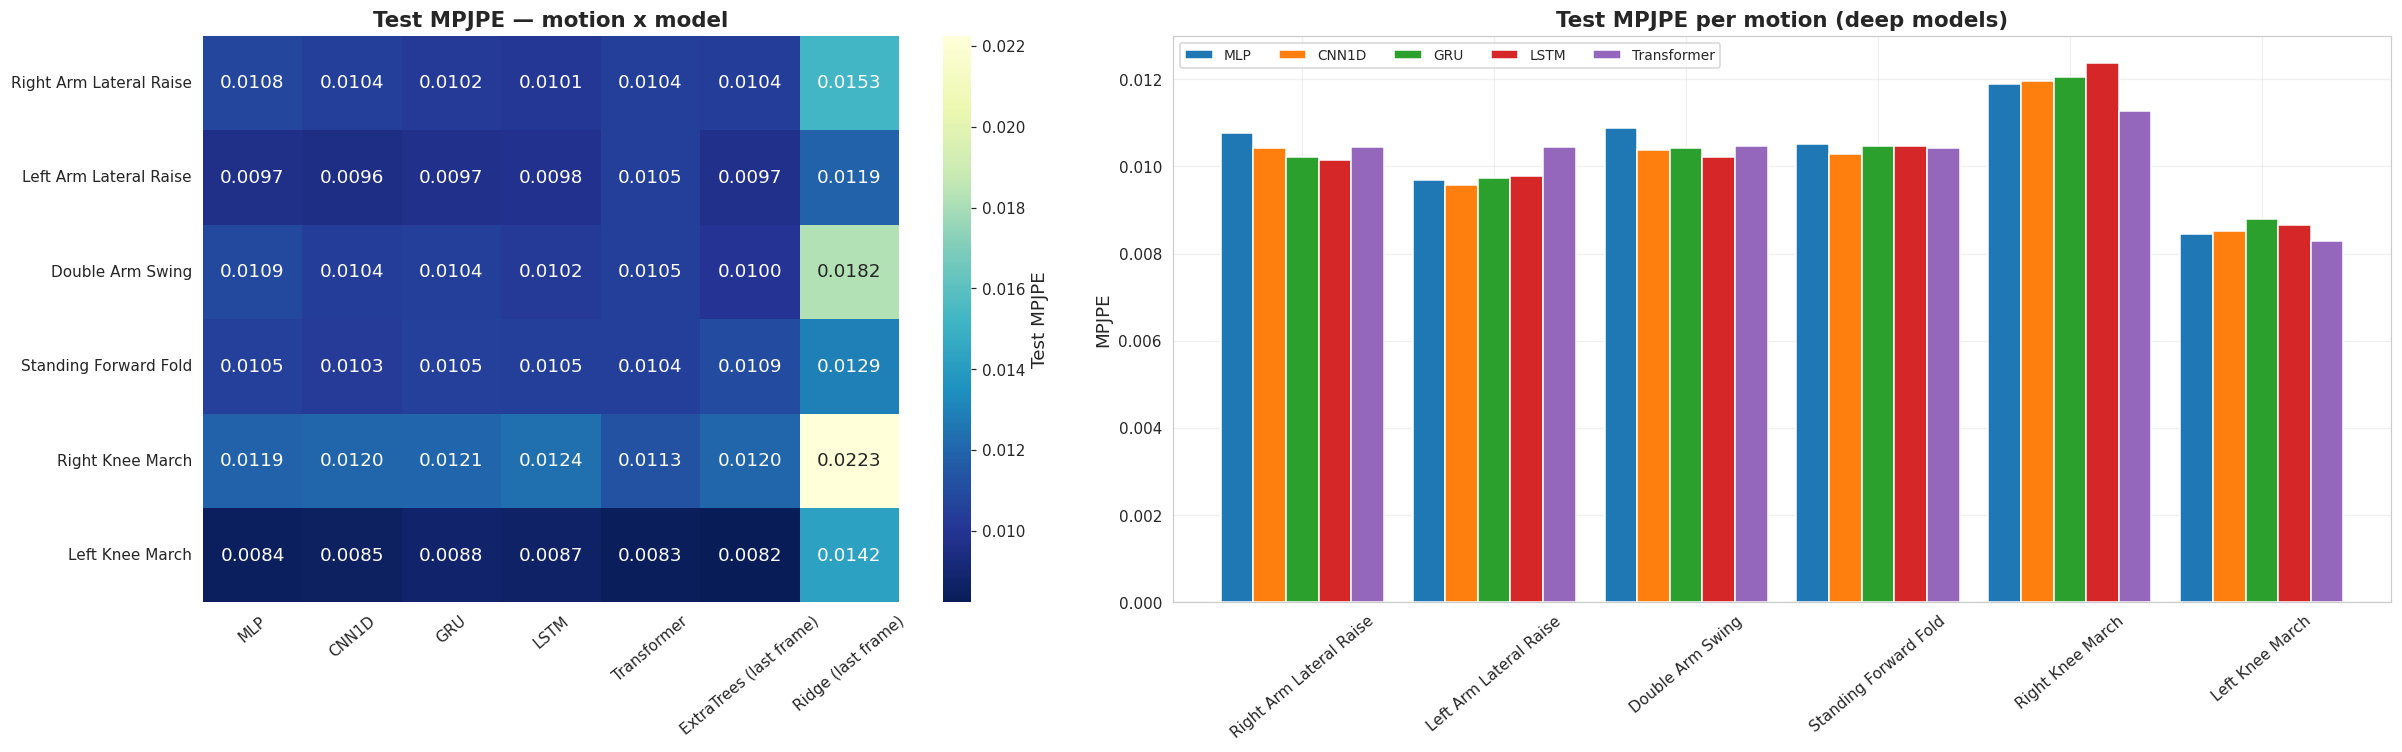

In [30]:
# Figures: MPJPE heatmap + grouped bars
fig, axes = plt.subplots(1, 2, figsize=(22, 7), gridspec_kw={"width_ratios": [1, 1.4]})
sns.heatmap(mpjpe_matrix, annot=True, fmt=".4f", cmap="YlGnBu_r", ax=axes[0], cbar_kws={"label": "Test MPJPE"})
axes[0].set_title("Test MPJPE — motion x model"); axes[0].set_ylabel(""); axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=40)

mpjpe_matrix[deep_cols].plot(kind="bar", ax=axes[1], width=0.85)
axes[1].set_title("Test MPJPE per motion (deep models)"); axes[1].set_ylabel("MPJPE"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=40); axes[1].legend(ncol=5, fontsize=9)
plt.tight_layout(); savefig("summary_mpjpe_all_motions.png"); plt.show()

# PART C — One model trained on the combined dataset (all 6 motions)

All 6 recordings are merged into **one** training set and the same five architectures are trained once on it.

How the combination respects the time-series structure:

1. Each motion keeps its own block-wise split, so every motion contributes train, validation **and** test frames.
2. The scalers are fit once on the **union of all motions' training rows**.
3. Sliding windows are built **per motion, per contiguous segment**, then concatenated. No window mixes frames
   from two motions or from two blocks.
4. The test windows are the same frames as in Part A, so the combined model can be compared with the
   single-motion models motion by motion. A `motion_id` is kept for every window for this breakdown
   (it is **not** an input to the model, the model only sees IMU data).
5. Per-motion metrics of the combined model use that motion's own train mean as the R² OOS benchmark and its own
   active-column set, so they are comparable with Part A (the pooled numbers use the all-motion train statistics).
6. The combined model does **pose regression for all 6 motions with one set of weights**. It is not told which motion
   is being performed and it does not output a motion label.


In [33]:
# ---- global scalers (training rows of all motions) ----
X_train_rows = np.concatenate([d["X_raw"][train_row_indices(d["segments"])] for d in MOTION_DATA.values()])
Y_train_rows = np.concatenate([d["Y_raw"][train_row_indices(d["segments"])] for d in MOTION_DATA.values()])
imu_scaler_all, pose_scaler_all = fit_scalers(X_train_rows, Y_train_rows)
joblib.dump(imu_scaler_all,  os.path.join(DIR_SCALERS, "ALL_imu_scaler.joblib"))
joblib.dump(pose_scaler_all, os.path.join(DIR_SCALERS, "ALL_pose_scaler.joblib"))

# ---- windows per motion, then concatenate (keep motion id for the per-motion breakdown) ----
buf = {s: {"X": [], "Y": [], "id": []} for s in ("train", "val", "test")}
for mi, (m, d) in enumerate(MOTION_DATA.items()):
    dd = split_arrays(scale_imu(imu_scaler_all, d["X_raw"]),
                      pose_scaler_all.transform(d["Y_raw"]).astype("float32"), d["segments"])
    for s in ("train", "val", "test"):
        buf[s]["X"].append(dd[s][0]); buf[s]["Y"].append(dd[s][1])
        buf[s]["id"].append(np.full(len(dd[s][0]), mi, dtype="int32"))

DATA_ALL = {s: (np.concatenate(buf[s]["X"]), np.concatenate(buf[s]["Y"])) for s in buf}
IDS_ALL  = {s: np.concatenate(buf[s]["id"]) for s in buf}

for s in ("train", "val", "test"):
    print(f"{s:5s}: X {DATA_ALL[s][0].shape}  Y {DATA_ALL[s][1].shape}")
assert not np.isnan(DATA_ALL["train"][0]).any() and not np.isnan(DATA_ALL["train"][1]).any()

per_motion_counts = pd.DataFrame({s: np.bincount(IDS_ALL[s], minlength=len(MOTIONS)) for s in ("train", "val", "test")},
                                 index=MOTIONS)
display(per_motion_counts)

# window boundaries inside the pooled test set (block seams and motion boundaries), for plots
TEST_BOUNDS = np.cumsum([w for d in MOTION_DATA.values() for w in test_seg_windows(d["segments"])])[:-1]
assert (TEST_BOUNDS < len(DATA_ALL["test"][0])).all()

# per-motion benchmark mean and active columns from each motion's OWN training rows (same as Part A)
PM_STATS = {}
for m, d in MOTION_DATA.items():
    yr = d["Y_raw"][train_row_indices(d["segments"])].astype("float64")
    PM_STATS[m] = dict(mean=yr.mean(axis=0), active=active_mask_from(yr.var(axis=0)))


train: X (15404, 10, 30)  Y (15404, 51)
val  : X (3610, 10, 30)  Y (3610, 51)
test : X (3676, 10, 30)  Y (3676, 51)


,train,val,test
Right Arm Lateral Raise,2348,546,558
Left Arm Lateral Raise,2454,573,584
Double Arm Swing,2372,554,564
Standing Forward Fold,2812,664,674
Right Knee March,2780,654,666
Left Knee March,2638,619,630


### C.1 Train the five models on the whole dataset

In [34]:
all_models, all_hist, all_time = {}, {}, {}
for mn, builder in MODEL_BUILDERS.items():
    print("\n" + "=" * 70); print(f"Training {mn} on ALL 6 motions ({N_SEEDS_COMBINED} seeds)"); print("=" * 70)
    ens, hist, secs = train_ensemble(mn, builder, DATA_ALL, pose_scaler_all, N_SEEDS_COMBINED,
                                     BATCH_SIZE_COMBINED, "ALL", use_ckpt=True)
    all_models[mn], all_hist[mn], all_time[mn] = ens, hist, secs
    print(f"{mn}: total training time {secs:.1f} s")

with open(os.path.join(DIR_RESULTS, "combined_training_history.json"), "w") as f:
    json.dump(all_hist, f)


Training MLP on ALL 6 motions (3 seeds)
    MLP         seed 0: 117 epochs | best  77 | train 0.0564 | val 0.0296
    MLP         seed 1: 136 epochs | best  96 | train 0.0557 | val 0.0291
    MLP         seed 2: 170 epochs | best 130 | train 0.0544 | val 0.0291
MLP: total training time 256.9 s

Training CNN1D on ALL 6 motions (3 seeds)
    CNN1D       seed 0: 149 epochs | best 109 | train 0.0546 | val 0.0303
    CNN1D       seed 1: 167 epochs | best 148 | train 0.0535 | val 0.0292
    CNN1D       seed 2: 130 epochs | best  90 | train 0.0561 | val 0.0295
CNN1D: total training time 282.7 s

Training GRU on ALL 6 motions (3 seeds)
    GRU         seed 0: 154 epochs | best 114 | train 0.0383 | val 0.0212
    GRU         seed 1: 116 epochs | best  76 | train 0.0392 | val 0.0219
    GRU         seed 2: 135 epochs | best  95 | train 0.0381 | val 0.0213
GRU: total training time 422.8 s

Training LSTM on ALL 6 motions (3 seeds)
    LSTM        seed 0: 109 epochs | best 100 | train 0.0363 | val

### C.2 Evaluate on the pooled test set (all motions) and compare with reference baselines

In [35]:
COMB, comb_rows = {}, []
for mn, ens in all_models.items():
    tr, va, te, inf, fps = evaluate_all_splits(ens, DATA_ALL, pose_scaler_all)
    COMB[mn] = dict(train=tr, val=va, test=te, n_params=ens.count_params(), training_time=all_time[mn],
                    inference_time=inf, fps=fps)
    comb_rows.append(make_row("ALL (combined)", mn, "deep", tr, va, te, ens.count_params(), all_time[mn], fps))
    print(f"{mn:12s} | Test MAE {te['mae']:.5f} | RMSE {te['rmse']:.5f} | MPJPE {te['mpjpe']:.5f} | "
          f"R2 {te['r2']:.4f} | R2 OOS {te['r2_oos']:.4f} | R2 active {te['r2_active']:.4f} | {fps:.0f} FPS")

REF_COMB = {}
for rn, rm in make_reference_models().items():
    t0 = time.time(); rm.fit(*DATA_ALL["train"]); secs = time.time() - t0
    tr, va, te, inf, fps = evaluate_all_splits(rm, DATA_ALL, pose_scaler_all)
    REF_COMB[rn] = dict(test=te)
    comb_rows.append(make_row("ALL (combined)", rn, "reference", tr, va, te, 0, secs, fps))

comb_df = pd.DataFrame(comb_rows).sort_values(["Type", "Test_MPJPE"]).reset_index(drop=True)
comb_df.to_csv(os.path.join(DIR_RESULTS, "combined_model_comparison.csv"), index=False)

best_comb = comb_df[comb_df.Type == "deep"].sort_values("Val_MPJPE").iloc[0]["Model"]   # selected on VALIDATION MPJPE
const_mpjpe = mpjpe(pose_scaler_all.inverse_transform(DATA_ALL["test"][1]),
                    np.tile(pose_scaler_all.mean_, (len(DATA_ALL["test"][1]), 1)))[0]
print(f"\nBest combined model (lowest pooled validation MPJPE): {best_comb}")
print(f"Constant train-mean baseline MPJPE on the pooled test set: {const_mpjpe:.5f}")
display(comb_df.style.format({c: "{:.5f}" for c in ["Train_MPJPE", "Val_MPJPE", "Test_MAE", "Test_RMSE", "Test_MPJPE",
                                                   "Test_R2", "Test_R2_OOS", "Test_R2_active"]}
                             | {"Test_over_Train": "{:.2f}", "Params": "{:,}"})
        .highlight_min(subset=["Test_MPJPE", "Test_MAE", "Test_RMSE"], color="lightgreen").hide(axis="index"))

MLP          | Test MAE 0.00617 | RMSE 0.01052 | MPJPE 0.01277 | R2 0.9622 | R2 OOS 0.9632 | R2 active 0.9182 | 4311 FPS
CNN1D        | Test MAE 0.00625 | RMSE 0.01073 | MPJPE 0.01292 | R2 0.9606 | R2 OOS 0.9617 | R2 active 0.9167 | 4175 FPS
GRU          | Test MAE 0.00554 | RMSE 0.00963 | MPJPE 0.01150 | R2 0.9683 | R2 OOS 0.9692 | R2 active 0.9320 | 3768 FPS
LSTM         | Test MAE 0.00550 | RMSE 0.00959 | MPJPE 0.01145 | R2 0.9686 | R2 OOS 0.9694 | R2 active 0.9313 | 3782 FPS
Transformer  | Test MAE 0.00559 | RMSE 0.00971 | MPJPE 0.01165 | R2 0.9678 | R2 OOS 0.9687 | R2 active 0.9307 | 3982 FPS

Best combined model (lowest pooled validation MPJPE): LSTM
Constant train-mean baseline MPJPE on the pooled test set: 0.04757


Motion,Model,Type,Params,TrainTime_s,FPS,Train_MPJPE,Val_MPJPE,Test_MAE,Test_RMSE,Test_MPJPE,Test_R2,Test_R2_OOS,Test_R2_active,Test_over_Train
ALL (combined),LSTM,deep,"34,835",446.070000,3782.000000,0.01317,0.01447,0.00550,0.00959,0.01145,0.96858,0.96943,0.93134,0.87
ALL (combined),GRU,deep,"28,947",422.840000,3768.000000,0.01339,0.01454,0.00554,0.00963,0.01150,0.96835,0.96920,0.93200,0.86
ALL (combined),Transformer,deep,"17,011",388.140000,3982.000000,0.01344,0.01472,0.00559,0.00971,0.01165,0.96783,0.96870,0.93067,0.87
ALL (combined),MLP,deep,"50,099",256.860000,4310.500000,0.01528,0.01642,0.00617,0.01052,0.01277,0.96220,0.96322,0.91821,0.84
ALL (combined),CNN1D,deep,"20,691",282.730000,4175.300000,0.01527,0.01622,0.00625,0.01073,0.01292,0.96065,0.96171,0.91674,0.85
ALL (combined),ExtraTrees (last frame),reference,0,12.200000,24551.300000,0.00925,0.01401,0.00526,0.00951,0.01106,0.96914,0.96998,0.93555,1.20
ALL (combined),Ridge (last frame),reference,0,0.010000,4182967.300000,0.03730,0.03929,0.01416,0.02705,0.02850,0.75007,0.75682,0.65063,0.76


### C.3 Combined-model results broken down per motion

TABLE C1: COMBINED MODELS — Test MPJPE on each motion (green = best in row)


Model,MLP,CNN1D,GRU,LSTM,Transformer
Motion,,,,,
Right Arm Lateral Raise,0.01260,0.01327,0.01158,0.01181,0.01134
Left Arm Lateral Raise,0.01398,0.01395,0.01211,0.01169,0.01305
Double Arm Swing,0.01312,0.01293,0.01228,0.01205,0.01230
Standing Forward Fold,0.01329,0.01318,0.01133,0.01141,0.01190
Right Knee March,0.01341,0.01400,0.01245,0.01250,0.01242
Left Knee March,0.01025,0.01022,0.00936,0.00931,0.00896


Saved figure -> figures/combined_mpjpe_per_motion.png


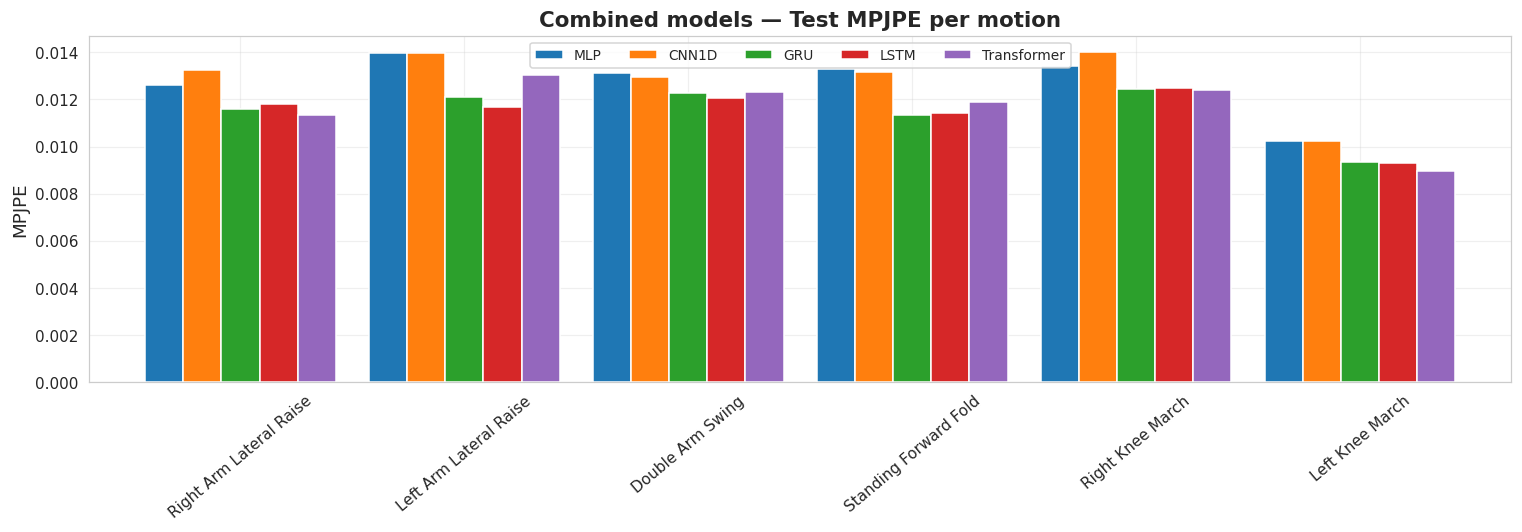

In [36]:
# Metrics of every combined model on the test windows of each motion (same frames as in Part A)
rows = []
for mn in MODEL_BUILDERS:
    yt, yp = COMB[mn]["test"]["y_true"], COMB[mn]["test"]["y_pred"]
    for mi, m in enumerate(MOTIONS):
        mask = IDS_ALL["test"] == mi
        mm = compute_metrics(yt[mask], yp[mask], pose_scaler_all,
                             bench_mean=PM_STATS[m]["mean"], active_mask=PM_STATS[m]["active"])
        rows.append(dict(Motion=m, Model=mn, MAE=mm["mae"], RMSE=mm["rmse"], MPJPE=mm["mpjpe"],
                         R2=mm["r2"], R2_OOS=mm["r2_oos"], R2_active=mm["r2_active"]))
comb_per_motion = pd.DataFrame(rows)
comb_per_motion.to_csv(os.path.join(DIR_RESULTS, "combined_model_per_motion.csv"), index=False)

pm_mpjpe = comb_per_motion.pivot(index="Motion", columns="Model", values="MPJPE").loc[MOTIONS][list(MODEL_BUILDERS)]
print("TABLE C1: COMBINED MODELS — Test MPJPE on each motion (green = best in row)")
display(pm_mpjpe.style.format("{:.5f}").highlight_min(axis=1, color="lightgreen"))

fig, ax = plt.subplots(figsize=(14, 5))
pm_mpjpe.plot(kind="bar", ax=ax, width=0.85)
ax.set_title("Combined models — Test MPJPE per motion"); ax.set_ylabel("MPJPE"); ax.set_xlabel("")
ax.tick_params(axis="x", rotation=40); ax.legend(ncol=5, fontsize=9)
plt.tight_layout(); savefig("combined_mpjpe_per_motion.png"); plt.show()

In [37]:
# Single-motion models (Part A) vs the ONE combined model (Part C), same test frames
best_single = table2.set_index("Motion")[["Model", "Test_MPJPE", "Test_R2_OOS"]].rename(
    columns={"Model": "Best_single_model", "Test_MPJPE": "Single_MPJPE", "Test_R2_OOS": "Single_R2_OOS"})
same_arch = mpjpe_matrix[best_comb].rename("Single_same_arch_MPJPE")      # Part A, same architecture as the combined model
cp = comb_per_motion[comb_per_motion.Model == best_comb].set_index("Motion")[["MPJPE", "R2_OOS"]].rename(
    columns={"MPJPE": "Combined_MPJPE", "R2_OOS": "Combined_R2_OOS"})
vs = best_single.join(cp).join(same_arch).loc[MOTIONS].reset_index()
vs["MPJPE_change_%"] = 100 * (vs["Combined_MPJPE"] - vs["Single_MPJPE"]) / vs["Single_MPJPE"]
vs["Change_vs_same_arch_%"] = 100 * (vs["Combined_MPJPE"] - vs["Single_same_arch_MPJPE"]) / vs["Single_same_arch_MPJPE"]
vs["Better"] = np.where(vs["Combined_MPJPE"] < vs["Single_MPJPE"], "combined", "single-motion")
mean_row = {"Motion": "MEAN", "Best_single_model": "-",
            "Single_MPJPE": vs.Single_MPJPE.mean(), "Single_R2_OOS": vs.Single_R2_OOS.mean(),
            "Combined_MPJPE": vs.Combined_MPJPE.mean(), "Combined_R2_OOS": vs.Combined_R2_OOS.mean(),
            "Single_same_arch_MPJPE": vs.Single_same_arch_MPJPE.mean(),
            "MPJPE_change_%": 100 * (vs.Combined_MPJPE.mean() - vs.Single_MPJPE.mean()) / vs.Single_MPJPE.mean(),
            "Change_vs_same_arch_%": 100 * (vs.Combined_MPJPE.mean() - vs.Single_same_arch_MPJPE.mean()) / vs.Single_same_arch_MPJPE.mean(),
            "Better": "-"}
vs = pd.concat([vs, pd.DataFrame([mean_row])], ignore_index=True)
vs.to_csv(os.path.join(DIR_RESULTS, "single_vs_combined.csv"), index=False)
print(f"TABLE C2: BEST SINGLE-MOTION MODEL (chosen on val) and SAME-ARCHITECTURE single model vs COMBINED {best_comb} "
      "(negative change = combined is better)")
display(vs.style.format({"Single_MPJPE": "{:.5f}", "Combined_MPJPE": "{:.5f}", "Single_same_arch_MPJPE": "{:.5f}",
                         "Single_R2_OOS": "{:.4f}", "Combined_R2_OOS": "{:.4f}",
                         "MPJPE_change_%": "{:+.1f}%", "Change_vs_same_arch_%": "{:+.1f}%"}).hide(axis="index"))
if N_SEEDS_MOTION != N_SEEDS_COMBINED:
    print(f"NOTE: single-motion models average {N_SEEDS_MOTION} seed(s), combined models {N_SEEDS_COMBINED}. "
          "Part of any gap comes from ensembling, not from more data. "
          "Set N_SEEDS_MOTION = N_SEEDS_COMBINED for a like-for-like comparison.")


TABLE C2: BEST SINGLE-MOTION MODEL (chosen on val) and SAME-ARCHITECTURE single model vs COMBINED LSTM (negative change = combined is better)


Motion,Best_single_model,Single_MPJPE,Single_R2_OOS,Combined_MPJPE,Combined_R2_OOS,Single_same_arch_MPJPE,MPJPE_change_%,Change_vs_same_arch_%,Better
Right Arm Lateral Raise,LSTM,0.01014,0.9770,0.01181,0.9726,0.01014,+16.6%,+16.6%,single-motion
Left Arm Lateral Raise,LSTM,0.00979,0.9657,0.01169,0.9585,0.00979,+19.5%,+19.5%,single-motion
Double Arm Swing,Transformer,0.01046,0.9839,0.01205,0.9790,0.01022,+15.2%,+17.9%,single-motion
Standing Forward Fold,GRU,0.01047,0.9257,0.01141,0.9141,0.01047,+8.9%,+8.9%,single-motion
Right Knee March,GRU,0.01206,0.9683,0.01250,0.9656,0.01238,+3.7%,+1.0%,single-motion
Left Knee March,LSTM,0.00866,0.9803,0.00931,0.9764,0.00866,+7.5%,+7.5%,single-motion
MEAN,-,0.01026,0.9668,0.01146,0.9610,0.01028,+11.7%,+11.5%,-


### C.4 Visualisation of the combined model

Saved figure -> figures/combined_training_curves.png


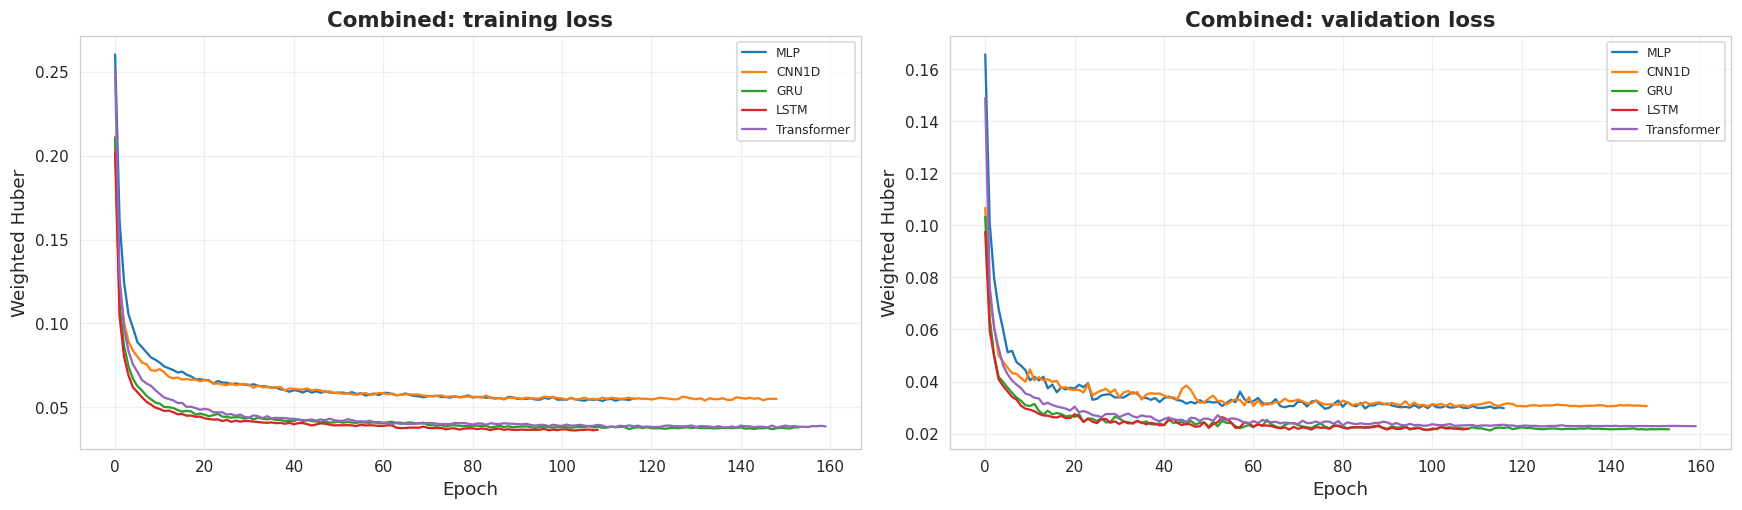

Saved figure -> figures/combined_model_comparison_bars.png


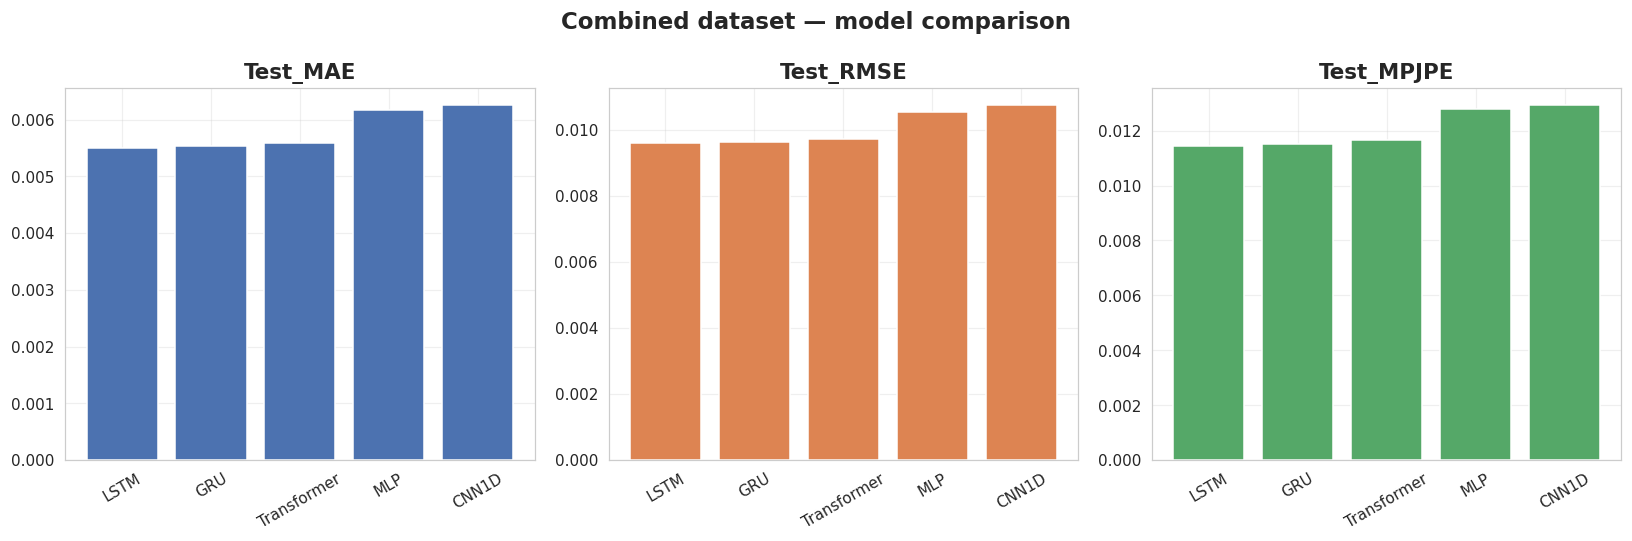

In [38]:
# Loss curves (seed 0) of the five combined models
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for mn, h in all_hist.items():
    axes[0].plot(h["loss"], label=f"{mn}");  axes[1].plot(h["val_loss"], label=f"{mn}")
axes[0].set_title("Combined: training loss"); axes[1].set_title("Combined: validation loss")
for a in axes: a.set_xlabel("Epoch"); a.set_ylabel("Weighted Huber"); a.legend(fontsize=8)
plt.tight_layout(); savefig("combined_training_curves.png"); plt.show()

# Comparison bar charts
cdf = comb_df[comb_df.Type == "deep"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, metric, color in zip(axes, ["Test_MAE", "Test_RMSE", "Test_MPJPE"], ["#4C72B0", "#DD8452", "#55A868"]):
    o = cdf.sort_values(metric)
    ax.bar(o["Model"], o[metric], color=color); ax.set_title(metric); ax.tick_params(axis="x", rotation=30)
plt.suptitle("Combined dataset — model comparison", fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("combined_model_comparison_bars.png"); plt.show()

Saved figure -> figures/combined_pred_vs_true_LSTM.png


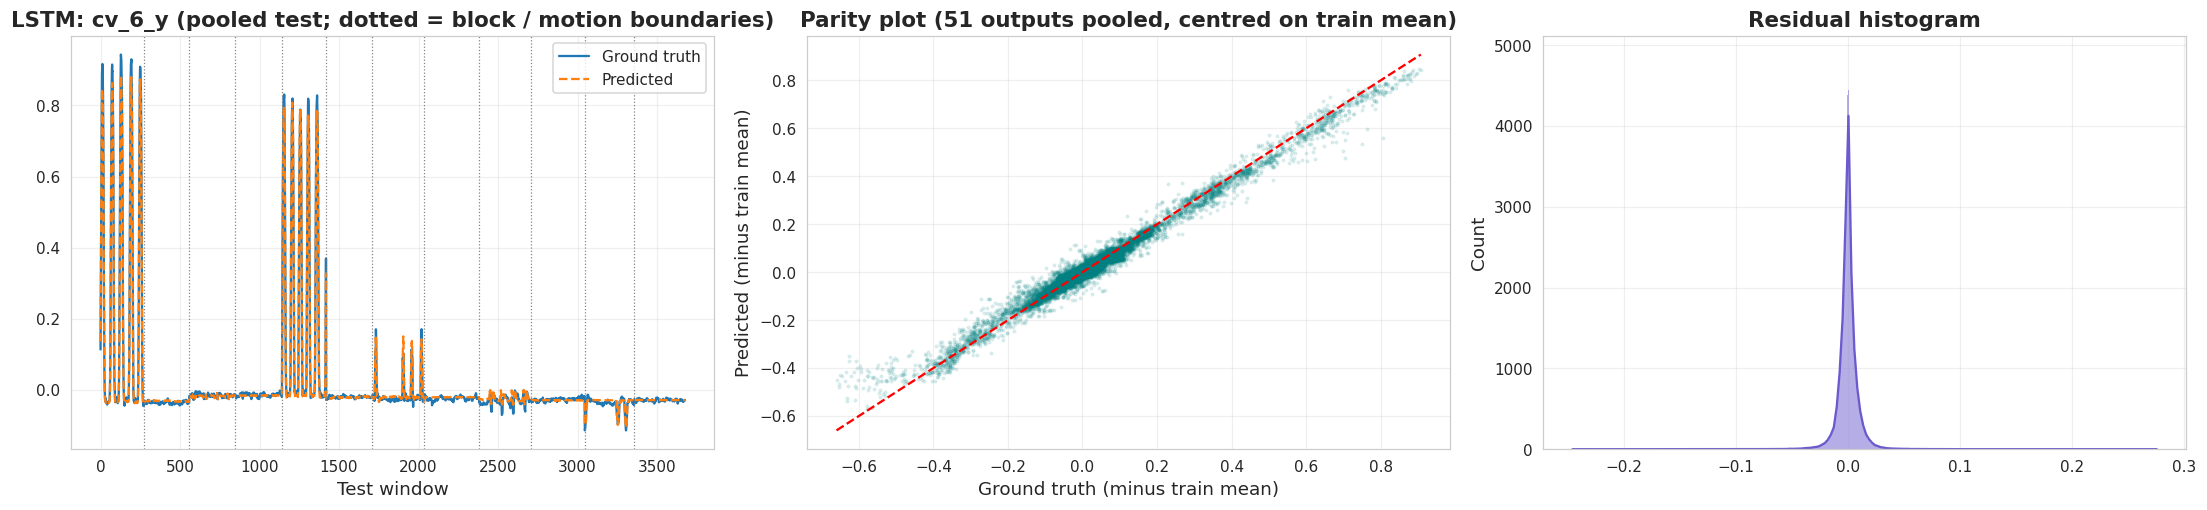

Saved figure -> figures/combined_joint_wise_mpjpe_LSTM.png


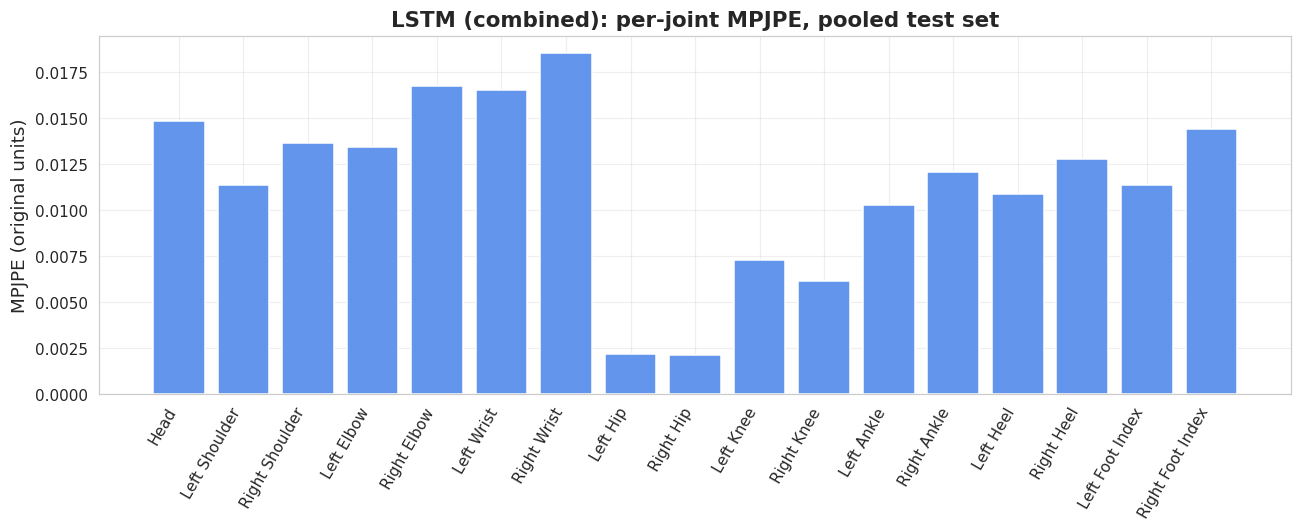

In [39]:
# Predicted vs ground truth, parity and residuals for the best combined model (pooled test set)
yt, yp = COMB[best_comb]["test"]["y_true"], COMB[best_comb]["test"]["y_pred"]
gmean = pose_scaler_all.mean_
j = int(np.argmax(yt.std(axis=0)))

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
axes[0].plot(yt[:, j], lw=1.5, label="Ground truth"); axes[0].plot(yp[:, j], "--", lw=1.5, label="Predicted")
for b_ in TEST_BOUNDS:
    axes[0].axvline(b_ - 0.5, color="gray", linestyle=":", lw=0.8)
axes[0].set_title(f"{best_comb}: {pose_cols[j]} (pooled test; dotted = block / motion boundaries)")
axes[0].set_xlabel("Test window"); axes[0].legend()

# parity on values centred by the train mean (otherwise between-joint offsets make any model look perfect)
ytc, ypc = (yt - gmean).flatten(), (yp - gmean).flatten()
axes[1].scatter(ytc, ypc, s=3, alpha=0.1, color="teal")
lim = [min(ytc.min(), ypc.min()), max(ytc.max(), ypc.max())]
axes[1].plot(lim, lim, "r--"); axes[1].set_title("Parity plot (51 outputs pooled, centred on train mean)")
axes[1].set_xlabel("Ground truth (minus train mean)"); axes[1].set_ylabel("Predicted (minus train mean)")
sns.histplot((yp - yt).flatten(), kde=True, ax=axes[2], color="slateblue"); axes[2].set_title("Residual histogram")
plt.tight_layout(); savefig(f"combined_pred_vs_true_{best_comb}.png"); plt.show()

# Per-joint MPJPE
plt.figure(figsize=(12, 5))
plt.bar(KEYPOINT_NAMES, COMB[best_comb]["test"]["per_joint_mpjpe"], color="cornflowerblue")
plt.xticks(rotation=60, ha="right"); plt.ylabel("MPJPE (original units)")
plt.title(f"{best_comb} (combined): per-joint MPJPE, pooled test set")
plt.tight_layout(); savefig(f"combined_joint_wise_mpjpe_{best_comb}.png"); plt.show()


Saved figure -> figures/combined_LSTM_Right_Arm_Lateral_Raise_3x3_skeleton.png


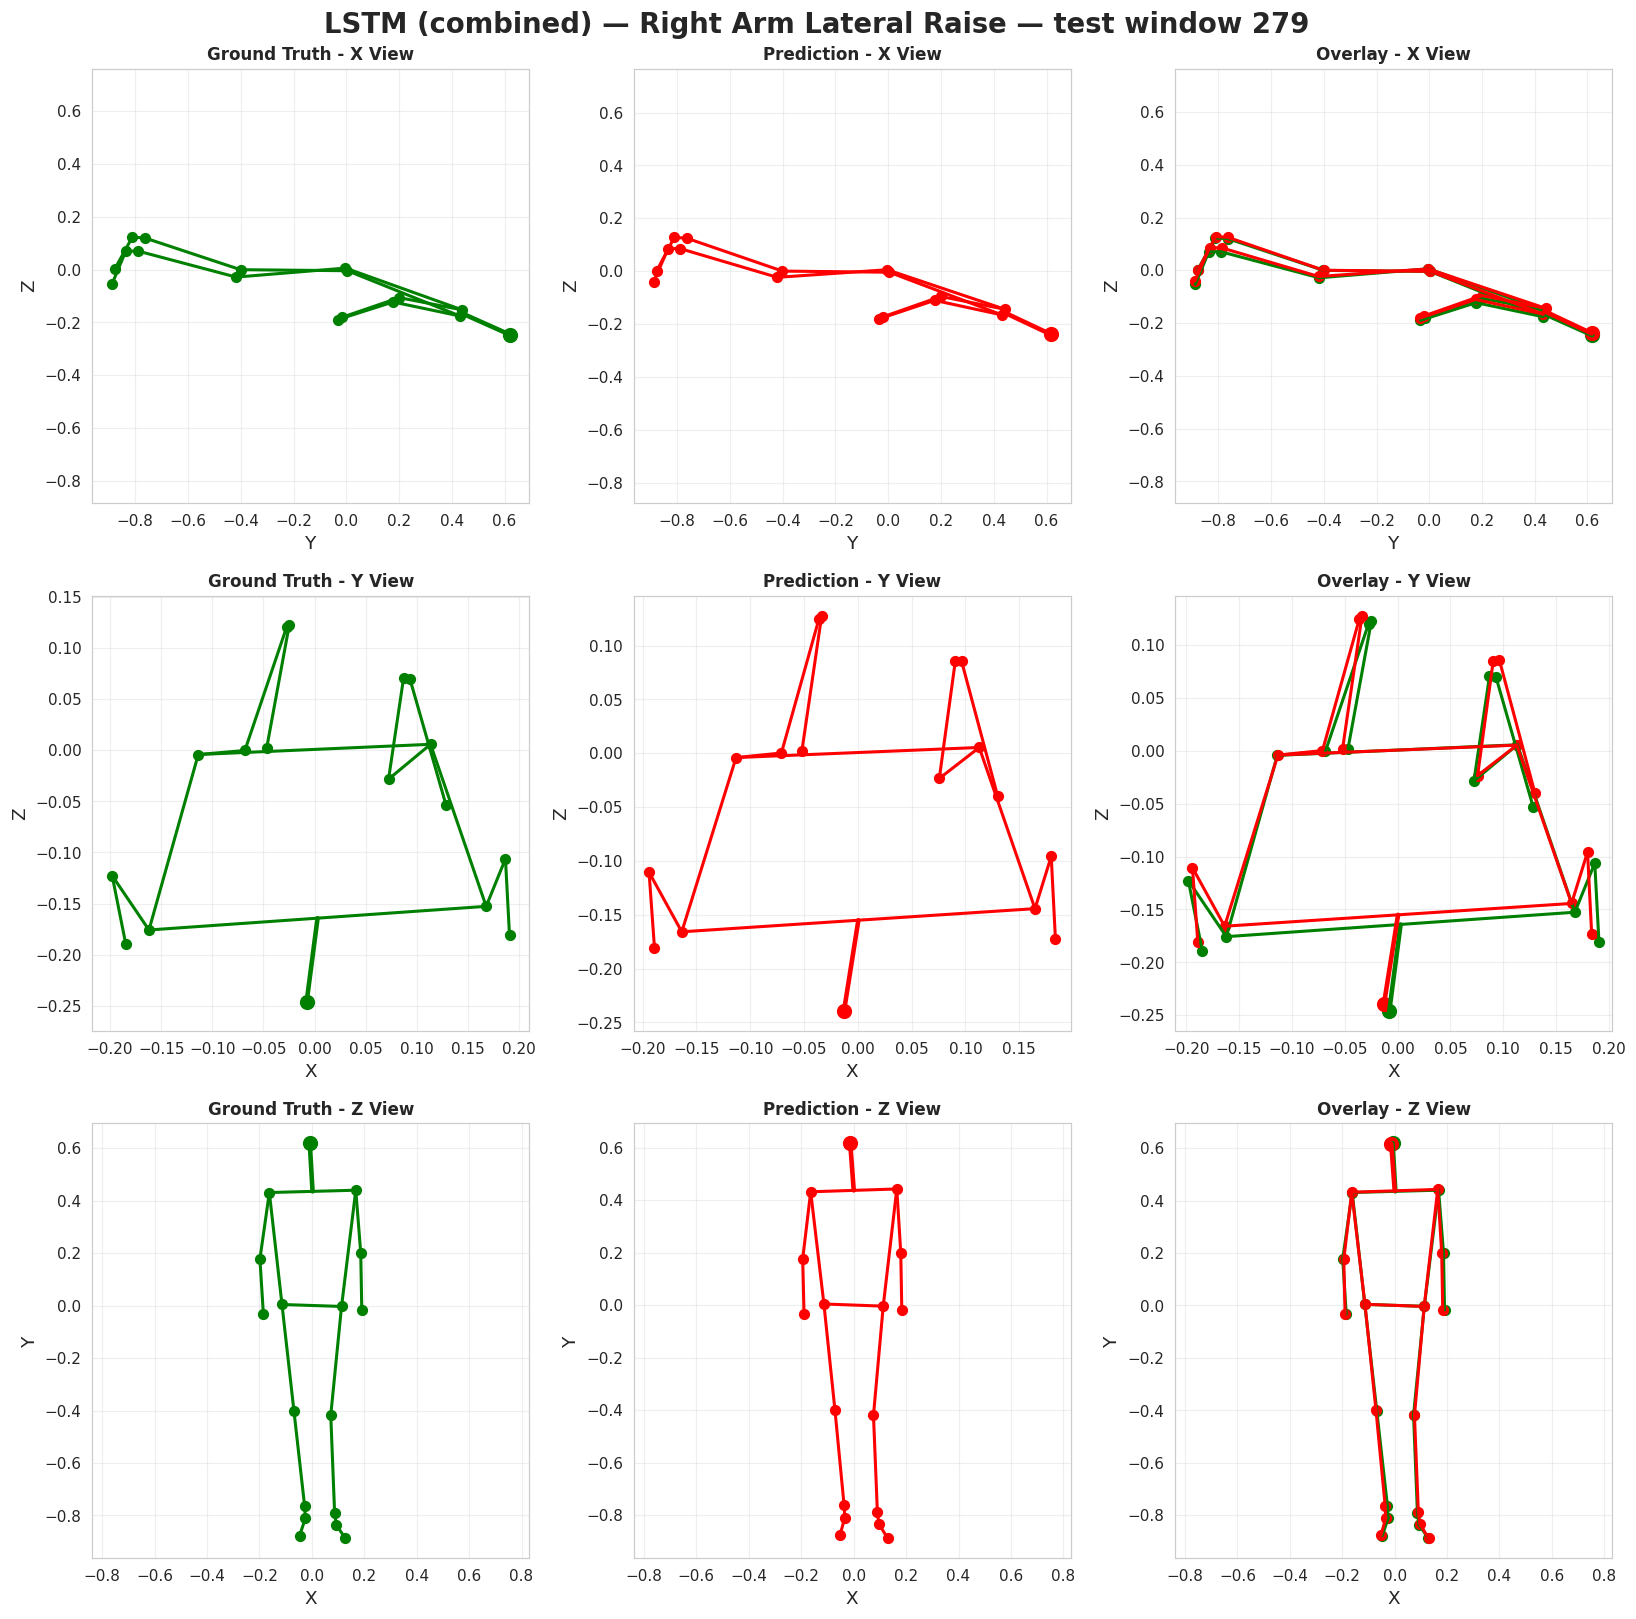

In [44]:
# 3x3 skeleton projection (ground truth / prediction / overlay) for one frame of EVERY motion would be 6 figures;
# here: the middle test frame of one motion. Change SKELETON_MOTION to look at another motion.
SKELETON_MOTION = MOTIONS[0]
mi = MOTIONS.index(SKELETON_MOTION)
idx = np.where(IDS_ALL["test"] == mi)[0]
fi = idx[len(idx) // 2]
plot_skeleton_3x3(yt[fi].reshape(N_JOINTS, 3), yp[fi].reshape(N_JOINTS, 3),
                  f"{best_comb} (combined) — {SKELETON_MOTION} — test window {fi}",
                  f"combined_{best_comb}_{safe_name(SKELETON_MOTION)}_3x3_skeleton.png")

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x

Saved animation -> figures/combined_skeleton_animation_Right_Arm_Lateral_Raise_LSTM.gif


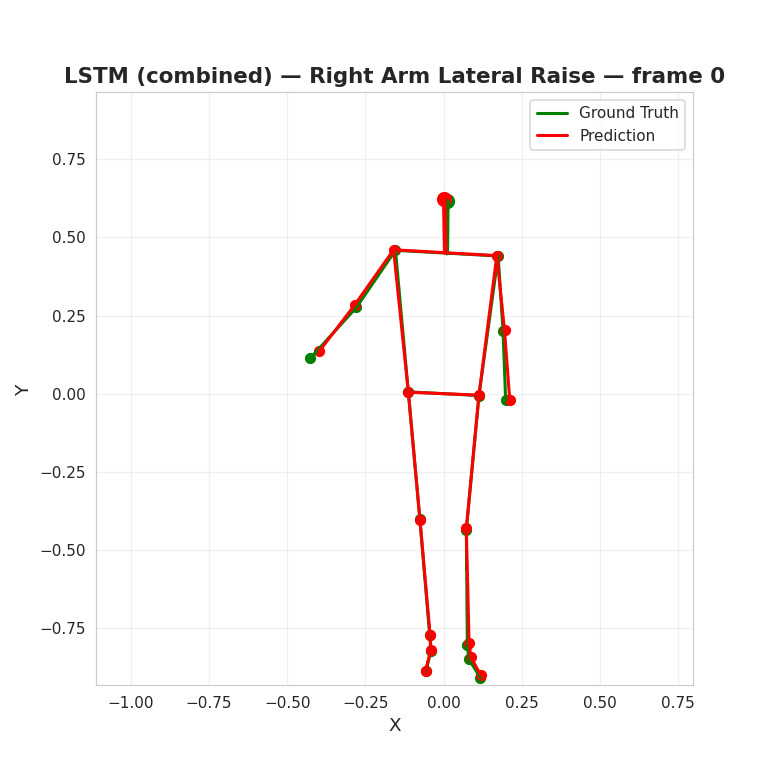

In [54]:
# Animated skeleton (Z view) for the first test windows of ANIM_MOTION
ANIM_MOTION = MOTIONS[0]
# first test segment only, so the animation never jumps across the seam between two test blocks
first_len = test_seg_windows(MOTION_DATA[ANIM_MOTION]["segments"])[0]
idx = np.where(IDS_ALL["test"] == MOTIONS.index(ANIM_MOTION))[0][:min(200, first_len)]
yt_a, yp_a = yt[idx], yp[idx]

fig, ax = plt.subplots(figsize=(7, 7))
pts = np.vstack([yt_a.reshape(-1, 3), yp_a.reshape(-1, 3)])
(xmin, ymin), (xmax, ymax) = pts[:, :2].min(0) - 0.02, pts[:, :2].max(0) + 0.02

def update(f):
    ax.clear()
    plot_projection(ax, yt_a[f].reshape(N_JOINTS, 3), "green", "Z")
    plot_projection(ax, yp_a[f].reshape(N_JOINTS, 3), "red", "Z")
    ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax); ax.set_aspect("equal")
    ax.set_title(f"{best_comb} (combined) — {ANIM_MOTION} — frame {f}")
    ax.plot([], [], color="green", lw=2, label="Ground Truth"); ax.plot([], [], color="red", lw=2, label="Prediction")
    ax.legend(loc="upper right")

anim = animation.FuncAnimation(fig, update, frames=len(idx), interval=50)      # 20 Hz = real time
anim_path = os.path.join(DIR_FIGURES, f"combined_skeleton_animation_{safe_name(ANIM_MOTION)}_{best_comb}.gif")
anim.save(anim_path, writer=animation.PillowWriter(fps=20))
plt.close(fig)
print("Saved animation ->", anim_path)
display(Image(filename=anim_path))

### C.5 Explainability: permutation importance of the 30 IMU channels (best combined model)

Saved figure -> figures/combined_permutation_importance.png


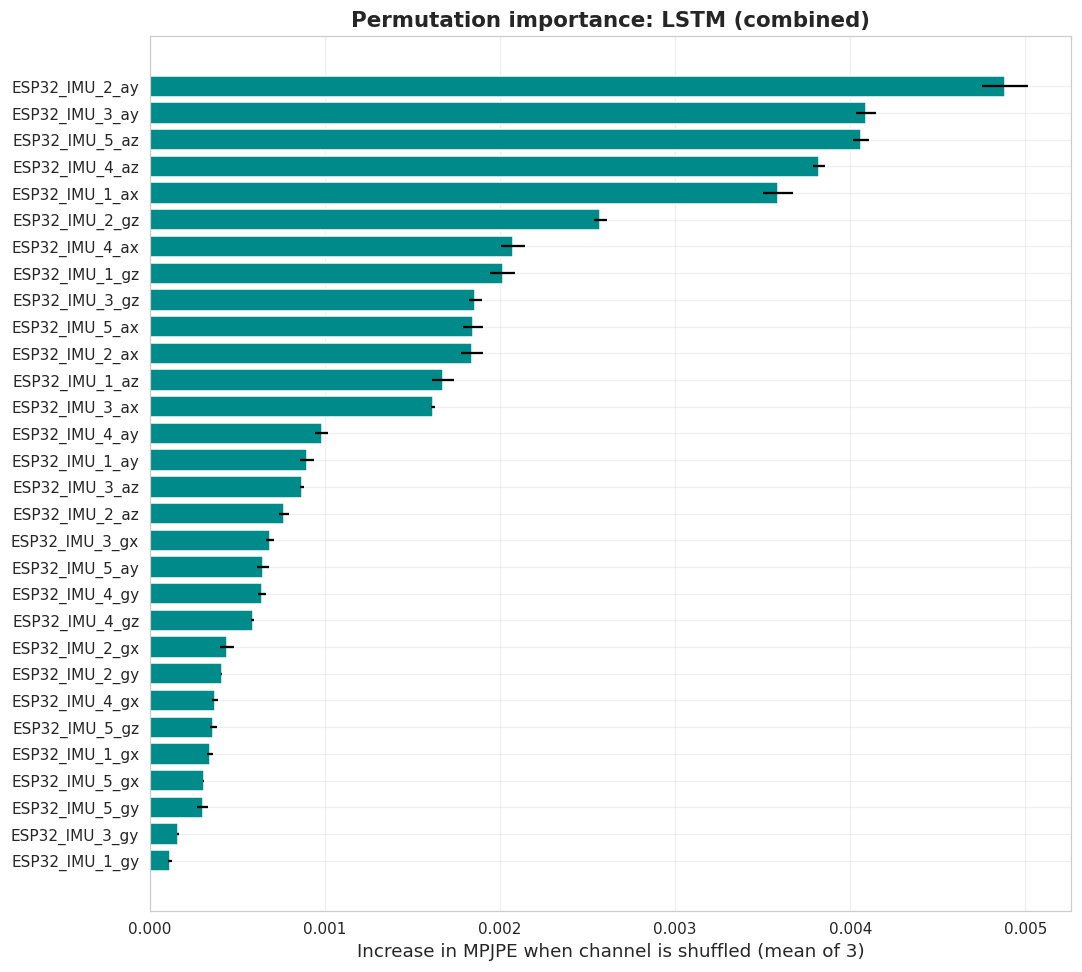

,IMU Channel,MPJPE Increase,Std
0,ESP32_IMU_2_ay,0.004881,0.000131
1,ESP32_IMU_3_ay,0.004088,0.000057
2,ESP32_IMU_5_az,0.004060,0.000044
3,ESP32_IMU_4_az,0.003822,0.000033
4,ESP32_IMU_1_ax,0.003588,0.000083


In [47]:
best_model = all_models[best_comb]
X_te = DATA_ALL["test"][0]
y_true_c = COMB[best_comb]["test"]["y_true"]
base_mpjpe = COMB[best_comb]["test"]["mpjpe"]

N_REPEATS = 3
rng = np.random.default_rng(SEED)
imp, imp_std = [], []
for fi_, fn in enumerate(imu_cols):
    deltas = []
    for _ in range(N_REPEATS):
        Xs = X_te.copy()
        Xs[:, :, fi_] = X_te[rng.permutation(len(X_te)), :, fi_]          # shuffle across test windows
        deltas.append(mpjpe(y_true_c, predict_orig(best_model, Xs, pose_scaler_all))[0] - base_mpjpe)
    imp.append(np.mean(deltas)); imp_std.append(np.std(deltas))

importance_df = pd.DataFrame({"IMU Channel": imu_cols, "MPJPE Increase": imp, "Std": imp_std}).sort_values(
    "MPJPE Increase", ascending=False).reset_index(drop=True)
importance_df.to_csv(os.path.join(DIR_RESULTS, "combined_permutation_importance.csv"), index=False)

plt.figure(figsize=(10, 9))
plt.barh(importance_df["IMU Channel"], importance_df["MPJPE Increase"], xerr=importance_df["Std"], color="darkcyan")
plt.gca().invert_yaxis(); plt.xlabel(f"Increase in MPJPE when channel is shuffled (mean of {N_REPEATS})")
plt.title(f"Permutation importance: {best_comb} (combined)")
plt.tight_layout(); savefig("combined_permutation_importance.png"); plt.show()
display(importance_df.head(5))


### C.6 Save combined artifacts and inference function

In [55]:
best_model.save(os.path.join(DIR_MODELS, "ALL_best_model_overall.keras"))   # writes ALL_best_model_overall_member{i}.keras
with open(os.path.join(DIR_RESULTS, "inference_config.json"), "w") as f:
    json.dump(dict(best_model=best_comb, window_size=WINDOW_SIZE, n_members=len(best_model.members),
                   split_mode=SPLIT_MODE, imu_cols=imu_cols, pose_cols=pose_cols, motions=MOTIONS), f, indent=2)
for mn, r in COMB.items():
    np.save(os.path.join(DIR_RESULTS, f"ALL_y_pred_test_{mn}.npy"), r["test"]["y_pred"])
np.save(os.path.join(DIR_RESULTS, "ALL_y_true_test.npy"), COMB[best_comb]["test"]["y_true"])
np.save(os.path.join(DIR_RESULTS, "ALL_test_motion_ids.npy"), IDS_ALL["test"])
with open(os.path.join(DIR_RESULTS, "motion_names.json"), "w") as f:
    json.dump(MOTIONS, f)
print("Saved combined model, scalers, predictions and tables in:", DIR_MODELS, DIR_SCALERS, DIR_RESULTS)


def predict_pose_from_imu(imu_window_df, model=None, imu_scaler=imu_scaler_all, pose_scaler=pose_scaler_all,
                          imu_columns=imu_cols, pose_columns=pose_cols, model_path=None):
    """imu_window_df: DataFrame with the 30 IMU columns and WINDOW_SIZE rows (oldest -> newest)."""
    if model is None:
        model = EnsembleModel.load(model_path)       # model_path e.g. "saved_models/ALL_best_model_overall.keras"
    X_new = imu_window_df[imu_columns].values.astype("float32")
    assert X_new.shape[0] == WINDOW_SIZE, f"Expected {WINDOW_SIZE} rows, got {X_new.shape[0]}"
    y = model.predict(scale_imu(imu_scaler, X_new)[None, ...], verbose=0)
    return pd.Series(pose_scaler.inverse_transform(y)[0], index=pose_columns)

# Demo: first test window of the first motion
seg_start = next(s for nm, s, e in MOTION_DATA[MOTIONS[0]]["segments"] if nm == "test")
demo = pd.DataFrame(MOTION_DATA[MOTIONS[0]]["X_raw"][seg_start:seg_start + WINDOW_SIZE], columns=imu_cols)
display(predict_pose_from_imu(demo, model=best_model).to_frame("predicted_value").T)
seg_true = MOTION_DATA[MOTIONS[0]]["Y_raw"][seg_start + WINDOW_SIZE - 1]
demo_pred = predict_pose_from_imu(demo, model=best_model).values
print(f"Demo MPJPE vs ground truth at the window's last frame: "
      f"{np.linalg.norm((demo_pred - seg_true).reshape(-1, 3), axis=1).mean():.5f}")


Saved combined model, scalers, predictions and tables in: saved_models saved_scalers results


,cv_0_x,cv_0_y,cv_0_z,cv_1_x,cv_1_y,cv_1_z,cv_2_x,cv_2_y,cv_2_z,cv_3_x,cv_3_y,cv_3_z,cv_4_x,cv_4_y,cv_4_z,cv_5_x,cv_5_y,cv_5_z,cv_6_x,cv_6_y,cv_6_z,cv_7_x,cv_7_y,cv_7_z,cv_8_x,...,cv_8_z,cv_9_x,cv_9_y,cv_9_z,cv_10_x,cv_10_y,cv_10_z,cv_11_x,cv_11_y,cv_11_z,cv_12_x,cv_12_y,cv_12_z,cv_13_x,cv_13_y,cv_13_z,cv_14_x,cv_14_y,cv_14_z,cv_15_x,cv_15_y,cv_15_z,cv_16_x,cv_16_y,cv_16_z
predicted_value,0.001854,0.62239,-0.218368,0.169875,0.44161,-0.134513,-0.160104,0.460291,-0.13639,0.194517,0.202456,-0.105322,-0.284312,0.283964,-0.089298,0.21117,-0.01988,-0.198546,-0.398266,0.135364,-0.169127,0.112764,-0.004477,0.004982,-0.112951,...,-0.003799,0.072342,-0.42991,-0.010929,-0.075899,-0.402056,-0.000076,0.081125,-0.795533,0.098668,-0.043486,-0.770198,0.124499,0.086593,-0.841639,0.098925,-0.040577,-0.818064,0.1277,0.119051,-0.900095,-0.027587,-0.057999,-0.884953,0.001615


Demo MPJPE vs ground truth at the window's last frame: 0.01151


# FINAL SUMMARY

In [56]:
print("=" * 78)
print("   FINAL SUMMARY — 6 MOTIONS: PER-MOTION MODELS vs ONE COMBINED MODEL")
print("=" * 78)

print("\n[1] Best single-motion model per motion (Part A)")
display(table2[["Motion", "Model", "Test_MAE", "Test_RMSE", "Test_MPJPE", "Test_R2", "Test_R2_OOS"]]
        .style.format({c: "{:.5f}" for c in ["Test_MAE", "Test_RMSE", "Test_MPJPE", "Test_R2", "Test_R2_OOS"]})
        .hide(axis="index"))

print("\n[2] Average of each architecture over the 6 motions (Part B)")
display(avg[["Mean_MAE", "Mean_RMSE", "Mean_MPJPE", "Mean_R2_OOS", "Mean_rank_among_deep", "Wins (best of 5 deep)"]]
        .style.format("{:.5f}", subset=["Mean_MAE", "Mean_RMSE", "Mean_MPJPE", "Mean_R2_OOS"])
        .format("{:.2f}", subset=["Mean_rank_among_deep"]))

print("\n[3] Models trained on the combined dataset — pooled test set (Part C)")
display(comb_df[comb_df.Type == "deep"][["Model", "Test_MAE", "Test_RMSE", "Test_MPJPE", "Test_R2", "Test_R2_OOS",
                                         "Test_R2_active", "FPS", "Params"]]
        .style.format({c: "{:.5f}" for c in ["Test_MAE", "Test_RMSE", "Test_MPJPE", "Test_R2", "Test_R2_OOS", "Test_R2_active"]}
                      | {"Params": "{:,}", "FPS": "{:.1f}"}).hide(axis="index"))

b = comb_df[comb_df.Model == best_comb].iloc[0]
print("\n" + "=" * 78)
print(f"BEST COMBINED MODEL (selected on validation MPJPE): {best_comb}")
print(f"  Test MAE {b.Test_MAE:.5f} | RMSE {b.Test_RMSE:.5f} | MPJPE {b.Test_MPJPE:.5f}")
print(f"  R2 (var-weighted) {b.Test_R2:.4f} | R2 OOS {b.Test_R2_OOS:.4f} | R2 active {b.Test_R2_active:.4f}")
print(f"  mean single-motion MPJPE {vs.iloc[-1].Single_MPJPE:.5f}  vs  combined {vs.iloc[-1].Combined_MPJPE:.5f} "
      f"({vs.iloc[-1]['MPJPE_change_%']:+.1f}%)")
print("=" * 78)

   FINAL SUMMARY — 6 MOTIONS: PER-MOTION MODELS vs ONE COMBINED MODEL

[1] Best single-motion model per motion (Part A)


Motion,Model,Test_MAE,Test_RMSE,Test_MPJPE,Test_R2,Test_R2_OOS
Right Arm Lateral Raise,LSTM,0.00485,0.00850,0.01014,0.97544,0.97697
Left Arm Lateral Raise,LSTM,0.00459,0.00795,0.00979,0.95474,0.96575
Double Arm Swing,Transformer,0.00486,0.00885,0.01046,0.98279,0.98386
Standing Forward Fold,GRU,0.00490,0.00876,0.01047,0.91663,0.92568
Right Knee March,GRU,0.00598,0.01102,0.01206,0.96461,0.96831
Left Knee March,LSTM,0.00421,0.00732,0.00866,0.97337,0.98030



[2] Average of each architecture over the 6 motions (Part B)


,Mean_MAE,Mean_RMSE,Mean_MPJPE,Mean_R2_OOS,Mean_rank_among_deep,Wins (best of 5 deep)
Model,,,,,,
CNN1D,0.00488,0.00870,0.01019,0.96733,2.17,2.000000
ExtraTrees (last frame),0.00486,0.00889,0.01021,0.96509,nan,nan
Transformer,0.00486,0.00884,0.01022,0.96592,2.83,2.000000
LSTM,0.00491,0.00873,0.01028,0.96687,3.00,2.000000
GRU,0.00491,0.00880,0.01028,0.96653,3.50,0.000000
MLP,0.00498,0.00884,0.01036,0.96633,3.50,0.000000
Ridge (last frame),0.00765,0.01551,0.01580,0.90901,nan,nan



[3] Models trained on the combined dataset — pooled test set (Part C)


Model,Test_MAE,Test_RMSE,Test_MPJPE,Test_R2,Test_R2_OOS,Test_R2_active,FPS,Params
LSTM,0.00550,0.00959,0.01145,0.96858,0.96943,0.93134,3782.0,"34,835"
GRU,0.00554,0.00963,0.01150,0.96835,0.96920,0.93200,3768.0,"28,947"
Transformer,0.00559,0.00971,0.01165,0.96783,0.96870,0.93067,3982.0,"17,011"
MLP,0.00617,0.01052,0.01277,0.96220,0.96322,0.91821,4310.5,"50,099"
CNN1D,0.00625,0.01073,0.01292,0.96065,0.96171,0.91674,4175.3,"20,691"



BEST COMBINED MODEL (selected on validation MPJPE): LSTM
  Test MAE 0.00550 | RMSE 0.00959 | MPJPE 0.01145
  R2 (var-weighted) 0.9686 | R2 OOS 0.9694 | R2 active 0.9313
  mean single-motion MPJPE 0.01026  vs  combined 0.01146 (+11.7%)
